# Energy Consumption Forecasting with Classical and Recurrent Models

The project aims to develop an energy consumption forecasting system based on both classical (ARIMA/SARIMA) and deep learning (LSTM) time series analysis techniques. The model will support energy analysis and planning decisions by providing reliable forecasts of future consumption trends.

The work is designed to be applicable to real-world time series and includes exploratory time series analysis, statistical property testing, model training and comparison, and quantitative evaluation of predictive performance.

Use cases: an analyst needs to estimate energy consumption in the hours/days following the last available data to support procurement decisions on the energy market.

The system will:

produce short-term forecasts with error estimates;
compare the reliability of classical statistical approaches versus recurrent neural networks.
Business importance: Improved quality of quantitative forecasts, reduced exposure to decisions based on unmodeled data, and support for systematic strategy development.

Dataset
File: clustered\_hourly\_values\_all.csv (downloadable from the following link: https://github.com/Profession-AI/progetti-ml/blob/main/Previsione%20del%20Consumo%20Energetico%20con%20Modelli%20Classici%20e%20Ricorrenti/clusteredhourlyvalues_all.csv)

The dataset contains 30 hourly time series derived from the dataset collected in the "The Smart Metering Electricity Customer Behavior Trials (CBTs)" project. The dataset contains electricity consumption data between 2009 and 2010 for more than 5,000 homes, businesses, and other businesses in Ireland. Each time series in the clustered\_hourly\_values\_all.csv file represents the average consumption (kWh) of a cluster of users with similar profiles.

This project focuses on three series selected for their distinct statistical characteristics:

cluster_26: both daily (24h) and weekly (168h) seasonality are marked; consumption varies significantly between time slots and between weekdays and weekends.

cluster_9: daily (24h) seasonality is present, weekly seasonality is absent; similar behavior across all days of the week.

cluster_24: no evident seasonality; essentially flat series with unstructured variations.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import zscore
%matplotlib inline
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import pickle
from pathlib import Path


from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Conv1D, MaxPooling1D, Flatten, Dropout
from tensorflow.keras.callbacks import EarlyStopping


import holidays

In [2]:
execute = True

### DATA IMPORT AND PREPROCESSING
here we import the data, using the date and time as index and filter only the data relative to clusters 9, 24 and 26

In [3]:
url = "https://raw.githubusercontent.com/Profession-AI/progetti-ml/2ee643c14d4af5c8c618ed6815d27663e3c7c703/Previsione%20del%20Consumo%20Energetico%20con%20Modelli%20Classici%20e%20Ricorrenti/clustered_hourly_values_all.csv"

df = pd.read_csv(url) # read the data

df.head()

,row ID,cluster_11,cluster_28,cluster_24,cluster_1,cluster_12,cluster_2,cluster_23,cluster_26,cluster_21,...,cluster_14,cluster_20,cluster_4,cluster_8,cluster_7,cluster_22,cluster_25,cluster_9,cluster_15,cluster_3
0,2009-07-15_00,0.198786,18.358000,0.777450,2.488265,9.594552,0.462515,0.391711,3.254085,0.357386,...,0.897384,0.598728,0.920695,0.875265,0.845983,0.658726,1.382476,1.037702,1.090514,0.947526
1,2009-07-15_01,0.171071,16.028357,0.591275,2.747633,7.681776,0.260338,0.398816,3.197561,0.364500,...,0.612620,0.395499,0.561120,0.650493,0.587325,0.438029,0.972665,0.730954,0.781937,0.580975
2,2009-07-15_02,0.162000,15.065393,0.483900,2.497571,6.972241,0.296500,0.396171,3.038390,0.361659,...,0.490683,0.324087,0.426242,0.522865,0.499978,0.346501,0.696608,0.518665,0.595129,0.452213
3,2009-07-15_03,0.189571,15.304214,0.353325,2.404000,6.804086,0.247176,0.399645,3.029756,0.349489,...,0.457262,0.303519,0.376581,0.469952,0.462120,0.334346,0.563122,0.423768,0.531196,0.416438
4,2009-07-15_04,0.320929,15.284107,0.378625,2.156265,6.595086,0.252132,0.411039,3.005634,0.347057,...,0.447911,0.283072,0.359359,0.485992,0.463902,0.314235,0.535823,0.382569,0.502776,0.398079


In [4]:
# convert in date-time format the row_ID colum data, rename it and set it as index for the dataframe

df["row ID"] = pd.to_datetime(df["row ID"].str.replace("_", " "))

df = df.rename(columns={"row ID": "datetime"})

df=df.set_index("datetime")


In [5]:
# Filter the data relative to the only clusters 26, 9 and 34

df = df[["cluster_26", "cluster_9", "cluster_24"]]

We observe that in the dataset there are no invalid values

In [6]:
df.isna().sum()

cluster_26    0
cluster_9     0
cluster_24    0
dtype: int64

In the dataset there are missing data relative to some days/hours, so we fill these values with a linear interpolation

In [7]:
df=df.asfreq("h")

print("Missing hours:", df.isna().sum())

print(df[df.isna().any(axis=1)])

df=df.interpolate(method="linear")


Missing hours: cluster_26    2
cluster_9     2
cluster_24    2
dtype: int64
                     cluster_26  cluster_9  cluster_24
datetime                                              
2010-03-28 01:00:00         NaN        NaN         NaN
2010-03-29 01:00:00         NaN        NaN         NaN


We save the data relative to the three clusters in three different time series

### WE SPLIT THE DATASET IN TRAINING AND TEST SET
we save the training and test data relative to any cluster in a different time series and save the test and train time series in two dictionaries with keys the name of the cluster

In [8]:
split_idx = int(len(df) * 0.8) # 8760
print("SPLIT INDEX: ", split_idx)
train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

SPLIT INDEX:  10272


In [10]:
series_9=train_df["cluster_9"]
series_24=train_df["cluster_24"]
series_26=train_df["cluster_26"]

series_9_test=test_df["cluster_9"]
series_24_test=test_df["cluster_24"]
series_26_test=test_df["cluster_26"]

In [11]:
series_list = {"9":series_9, "24":series_24, "26":series_26}
series_list_test = {"9":series_9_test, "24":series_24_test, "26":series_26_test}

In [12]:
series_9.tail()

datetime
2010-09-15 19:00:00    1.690426
2010-09-15 20:00:00    1.900271
2010-09-15 21:00:00    2.009429
2010-09-15 22:00:00    1.687352
2010-09-15 23:00:00    1.374155
Freq: h, Name: cluster_9, dtype: float64

### QUALITATIVE DATA ANALYSIS AND VISUALIZATION
we visualize the three series

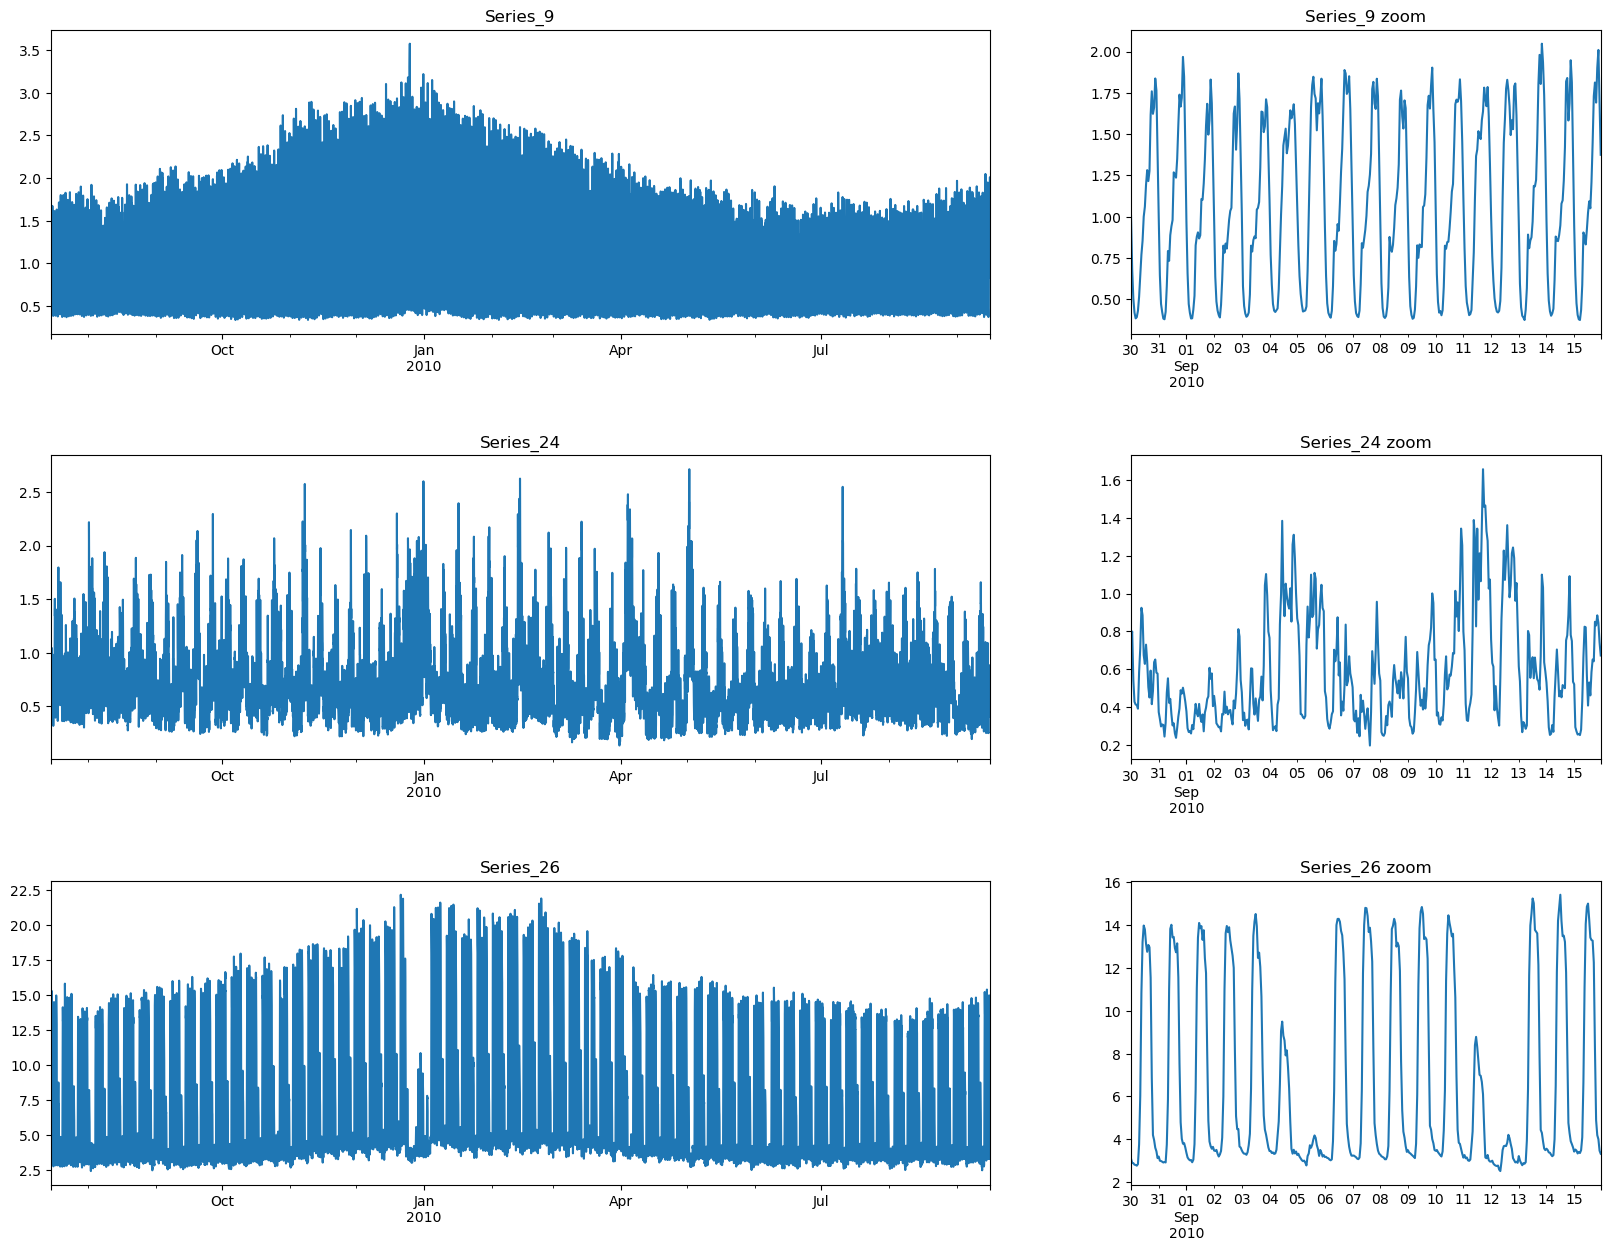

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(20,15),gridspec_kw={'width_ratios': [2, 1]})
#fig.suptitle("Series ", fontsize=16)

fig.subplots_adjust(hspace=.4)

series_9.plot(title="Series_9", ax=axes[0,0])
series_24.plot(title="Series_24", ax=axes[1,0])
series_26.plot(title="Series_26", ax=axes[2,0])
series_9.loc["2010-08-30":].plot(title="Series_9 zoom", ax=axes[0,1])
series_24.loc["2010-08-30":].plot(title="Series_24 zoom", ax=axes[1,1])
series_26.loc["2010-08-30":].plot(title="Series_26 zoom", ax=axes[2,1])

for ax in axes.flatten():
    ax.tick_params(axis='x', labelrotation=0)
    ax.set_xlabel(None)


We observe a seasonal trend both in clusters 9 and 26, not in 24. In all the series we observe a weekly and daily periodicity.  

Next we investigate deeper how the energy consuption varies with the day time

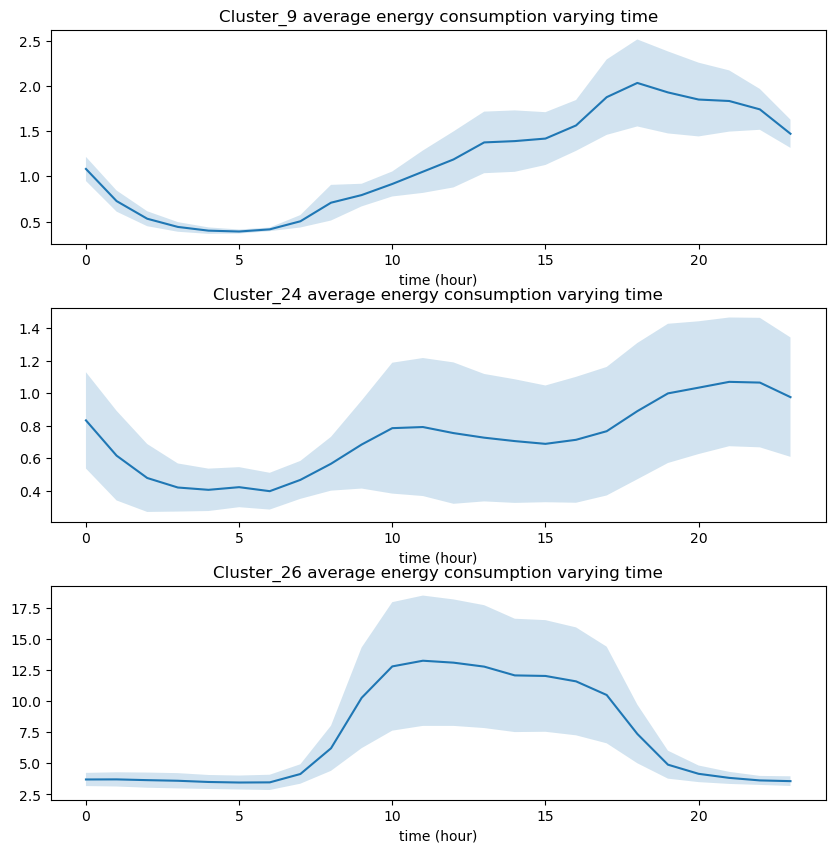

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10,10))
fig.subplots_adjust(hspace=.3)
i=0

for name,series in series_list.items():
    hour_mean = series.groupby(series.index.hour).mean()  # we compute the average consuption at each time
    hour_std = series.groupby(series.index.hour).std()
    ax=axes[i]
    ax.plot(hour_mean.index, hour_mean, marker="", linestyle="-")
    ax.fill_between(hour_std.index, hour_mean - hour_std, hour_mean + hour_std, alpha=0.2, label="± 1 standard deviation")
    ax.tick_params(axis='x', labelrotation=0)
    ax.set_title(f"Cluster_{name} average energy consumption varying time")
    ax.set_xlabel("time (hour)")
    i=i+1


In all the clusters we observe higher consuptions during the day and smaller in the night.

Next we study how varies the energy consuption across the three different clusters varying the day of the week.

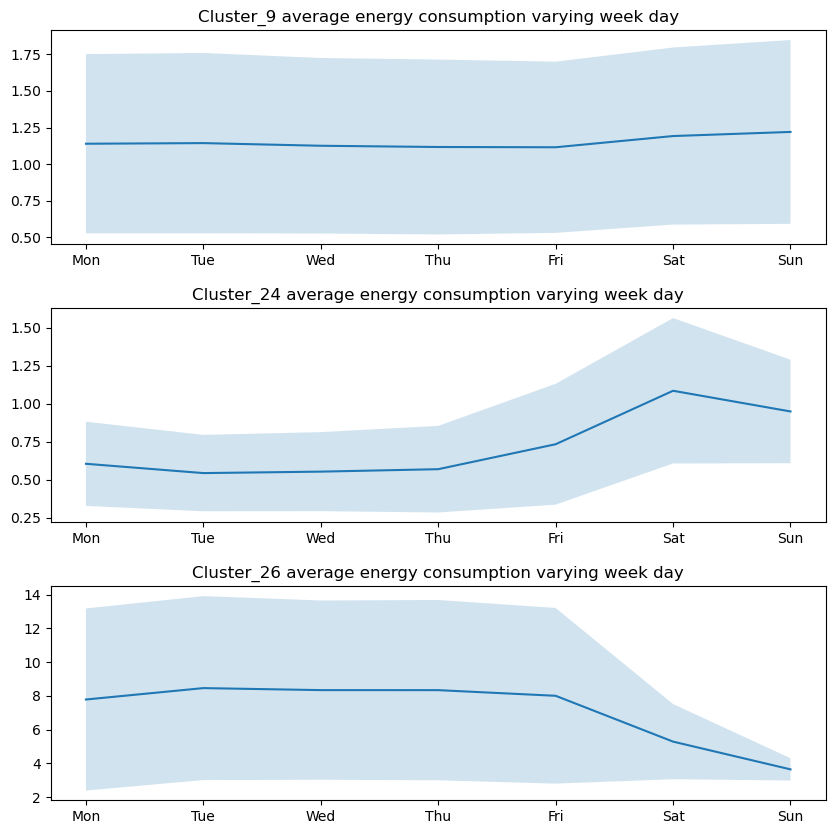

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(10,10))
fig.subplots_adjust(hspace=.3)
i=0

for name,series in series_list.items():
    weekly_mean = series.groupby(series.index.dayofweek).mean()   # average consumption for day of the week
    weekly_std = series.groupby(series.index.dayofweek).std()   # std of consuption for day of the week
    days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    ax=axes[i]
    ax.plot(days, weekly_mean, marker="", linestyle="-")
    ax.fill_between(days,weekly_mean - weekly_std, weekly_mean + weekly_std, alpha=0.2, label="± 1 standard deviation")
    ax.tick_params(axis='x', labelrotation=0)
    ax.set_title(f"Cluster_{name} average energy consumption varying week day")
    i=i+1


In all the three clusters we observe significant differences in the consuption of energy between working days and week-ends. In particular the energy consuption is higher during the working days in cluster 26 and lower in clusters 24 and 9.

Last we study how the consuption of energy varies during the year. To this end we consider a 30-days rolling mean to smoothen the daily and weekly periodicities.

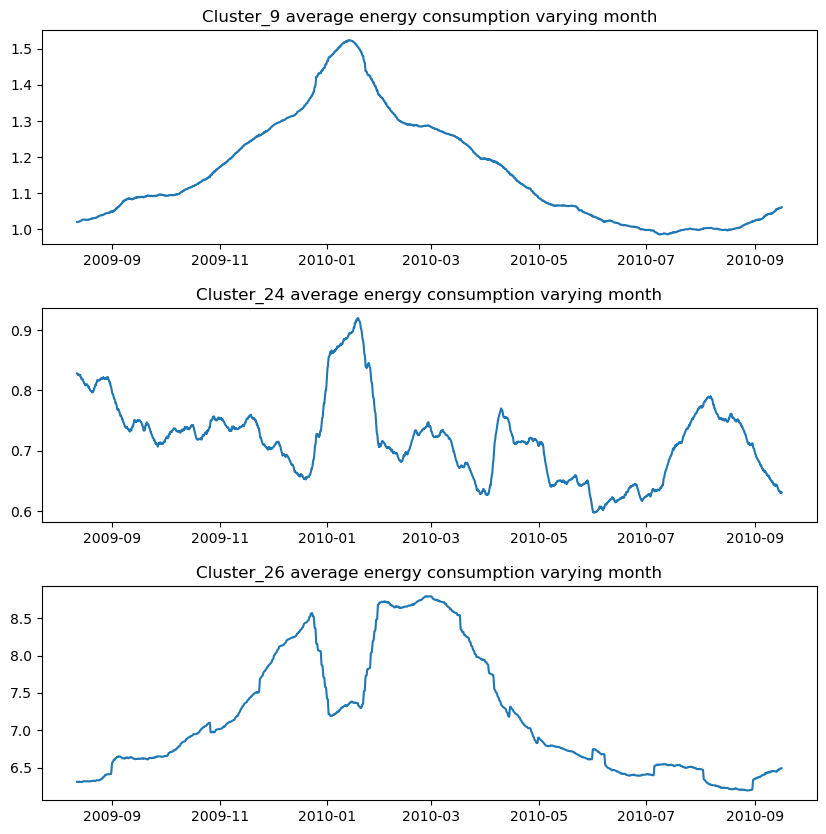

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10,10))
fig.subplots_adjust(hspace=.3)
i=0

for name,series in series_list.items():
    rolling_mean = series.rolling(672).mean()
    ax=axes[i]
    ax.plot(rolling_mean.index, rolling_mean, marker="", linestyle="-")
    ax.tick_params(axis='x', labelrotation=0)
    ax.set_title(f"Cluster_{name} average energy consumption varying month")
    i=i+1

From this study it is particularly evident a difference in the energy consuption between winter and summer months both in cluster 9 and 26. Differently cluster 24 seems not to be affected from this phenomenon. We also see a significant difference in the energy consuption during the Christam holidays in all the three clusters.

## Feature Engineering

since the energy consuption varies significantly according to the day of the week and during the holdays we include two features one indicating weather a day is a standard working day of the week a saturday where only part of the population works or saturday. Second we include  a feature to check wheather a certain day is a public holiday in Ireland, third we include a feature that is periodic in the month with a maximum in december and a minimum in august.

In [17]:
ie_holidays = holidays.Ireland(years=[2009, 2010])

df["day_type"] = df.index.dayofweek.map({0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 1, 6: 2})
df["is_holiday"] = df.index.normalize().isin(ie_holidays).astype(int)
df["month_sin"] = np.sin(2 * np.pi * (df.index.month) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df.index.month) / 12)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

# create the series with the additional features
Ftr_train = train_df[["day_type", "is_holiday", "month_sin", "month_cos"]]
Ftr_test = test_df[["day_type", "is_holiday", "month_sin", "month_cos"]]

### Monthly normalization for SARIMAX

For each series, the training-set mean and standard deviation are estimated separately for each calendar month. The normalized training series are used in the ACF/PACF inspection and in the SARIMAX fits. Statistics are saved in `monthly_stats` and later used to invert forecasts to the original energy scale.

The normalization is $$(value - monthly\_mean) / monthly\_stdev$$


In [18]:
monthly_stats = {}
series_list_monthly = {}
series_list_test_monthly = {}

def fit_monthly_stats(train_series):
    stats = {}
    for month, values in train_series.groupby(train_series.index.month):
        mean = float(values.mean())
        std = float(values.std(ddof=0))
        stats[int(month)] = {"mean": mean, "std": std}
    return stats

def transform_monthly(series, stats):
    means = np.array([stats[int(month)]["mean"] for month in series.index.month])
    stds = np.array([stats[int(month)]["std"] for month in series.index.month])
    return pd.Series((series.to_numpy() - means) / stds, index=series.index, name=series.name)

def inverse_monthly(series, stats):
    means = np.array([stats[int(month)]["mean"] for month in series.index.month])
    stds = np.array([stats[int(month)]["std"] for month in series.index.month])
    return pd.Series(series.to_numpy() * stds + means, index=series.index, name=series.name)

for name, train_series in series_list.items():
    monthly_stats[name] = fit_monthly_stats(train_series)
    series_list_monthly[name] = transform_monthly(train_series, monthly_stats[name])
    series_list_test_monthly[name] = transform_monthly(series_list_test[name], monthly_stats[name])


rows = []
for name, stats_by_month in monthly_stats.items():
    for month, values in stats_by_month.items():
        rows.append({
            "series": name,
            "month": month,
            "mean": values["mean"],
            "std": values["std"],
        })

stats_df = pd.DataFrame(rows).sort_values(["series", "month"])
stats_df.to_csv("monthly_stats_by_series.csv", index=False)

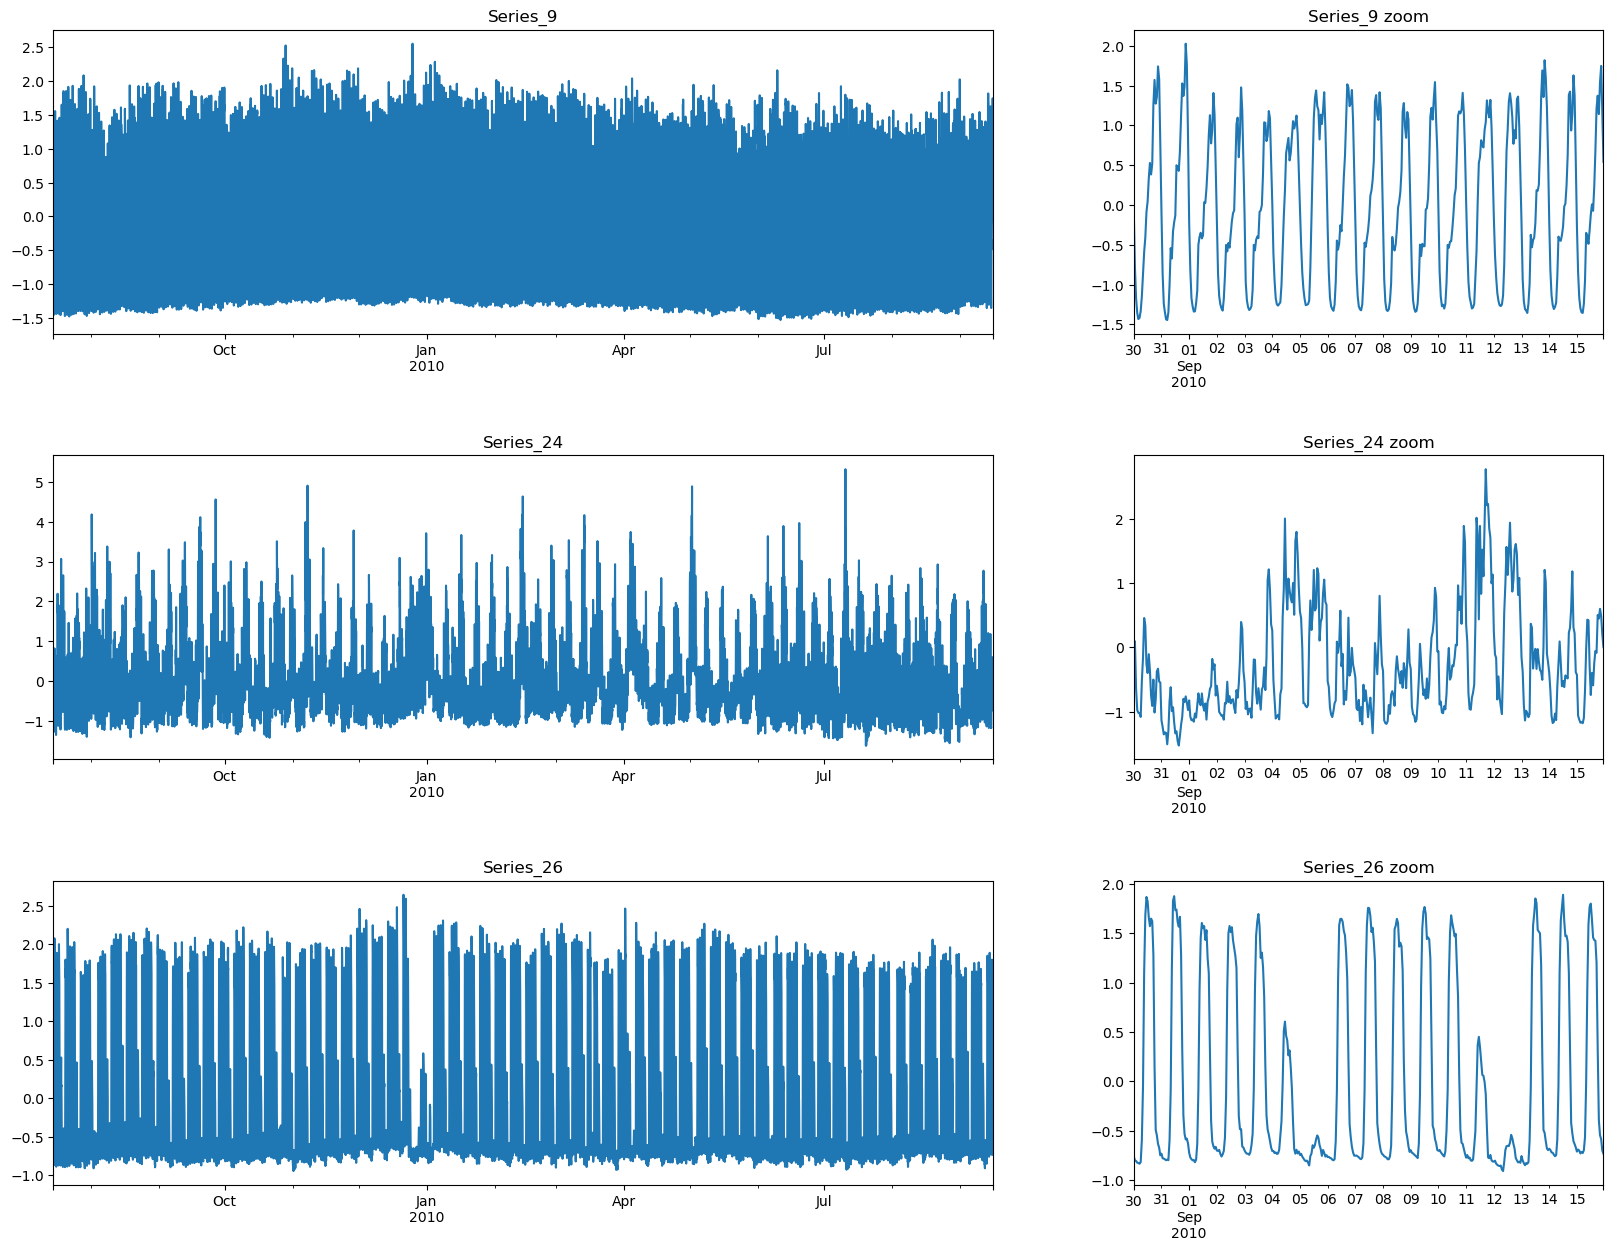

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(20,15),gridspec_kw={'width_ratios': [2, 1]})
#fig.suptitle("Series ", fontsize=16)

fig.subplots_adjust(hspace=.4)

series_list_monthly["9"].plot(title="Series_9", ax=axes[0,0])
series_list_monthly["24"].plot(title="Series_24", ax=axes[1,0])
series_list_monthly["26"].plot(title="Series_26", ax=axes[2,0])
series_list_monthly["9"].loc["2010-08-30":].plot(title="Series_9 zoom", ax=axes[0,1])
series_list_monthly["24"].loc["2010-08-30":].plot(title="Series_24 zoom", ax=axes[1,1])
series_list_monthly["26"].loc["2010-08-30":].plot(title="Series_26 zoom", ax=axes[2,1])

for ax in axes.flatten():
    ax.tick_params(axis='x', labelrotation=0)
    ax.set_xlabel(None)


Next we visualize autocorrelation (ACF) and partial autocorrelation (PACF) plots for the three series and perform Augmented Dickey-Fuller test to assess their stationarity

Augmented Dickey-Fuller test on series 9: statistics - -11.425644382431678, p value - 6.706006033040284e-21
Augmented Dickey-Fuller test on series 24: statistics - -17.039917230698766, p value - 8.210320454624153e-30
Augmented Dickey-Fuller test on series 26: statistics - -14.883122645981766, p value - 1.5982689572199205e-27


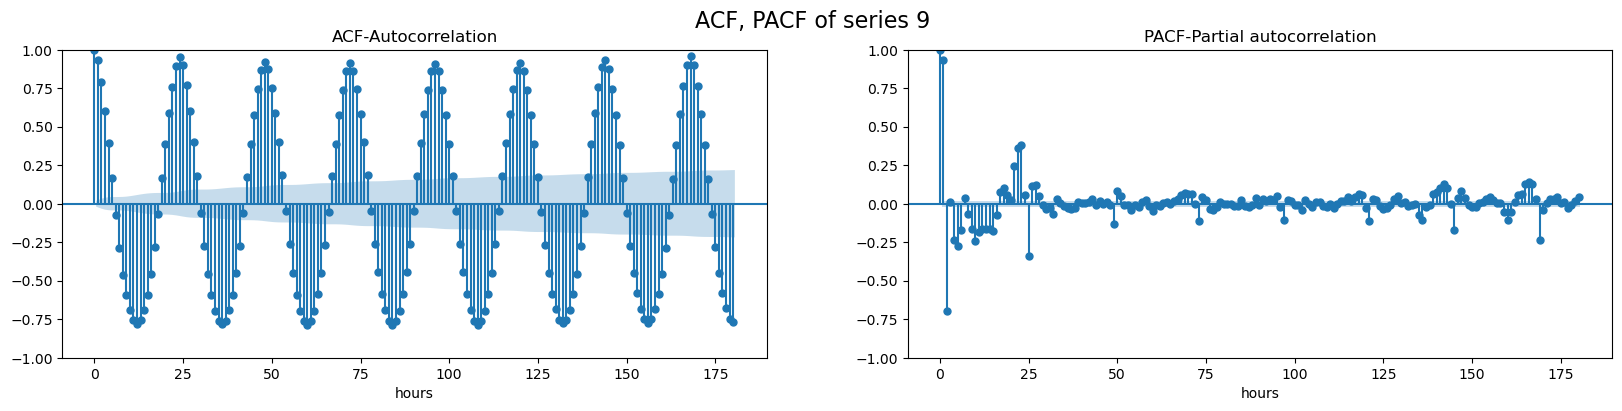

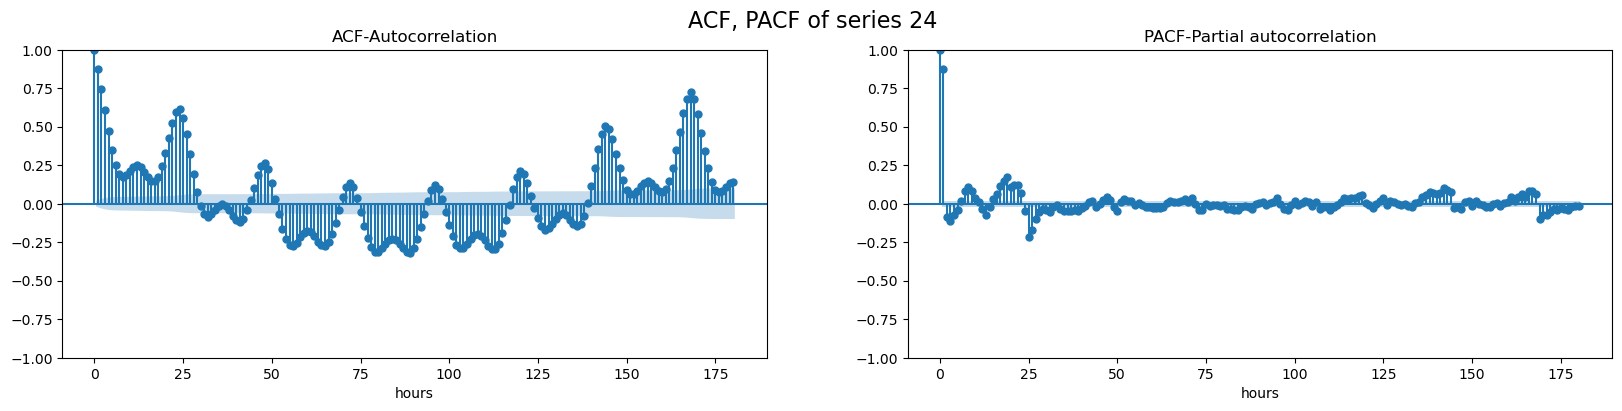

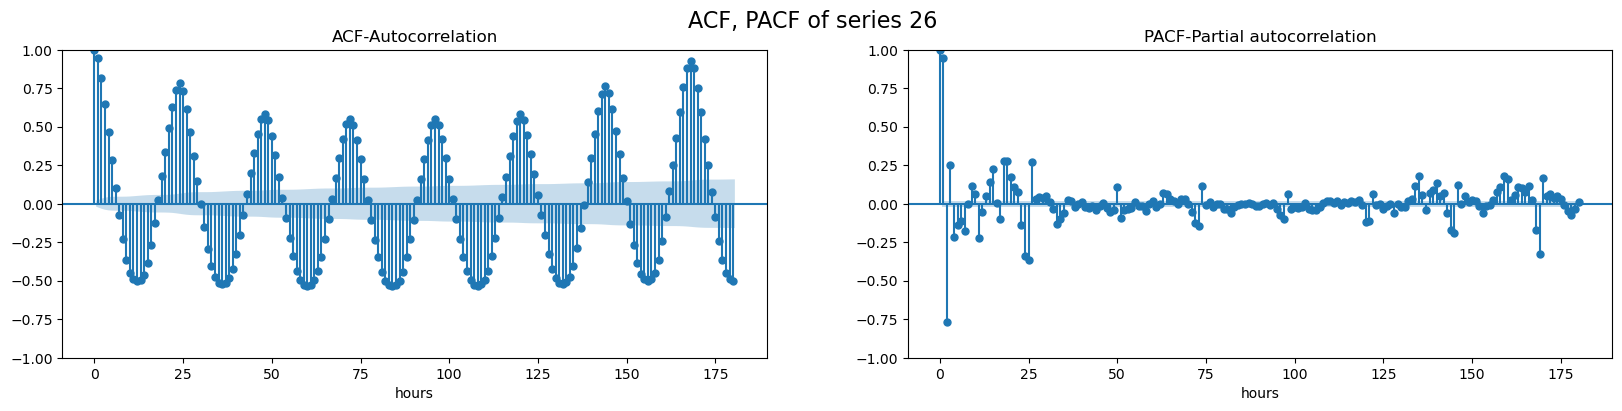

In [20]:
for name,series in series_list_monthly.items():
    adf=adfuller(series)
    p_value = adf[1]
    ADF_statistic = adf[0]
    print(f"Augmented Dickey-Fuller test on series {name}: statistics - {ADF_statistic}, p value - {p_value}")
    fig, axes = plt.subplots(1, 2, figsize=(20,4))
    fig.suptitle(f"ACF, PACF of series {name}", fontsize=16)
    plot_acf(series,lags=180,ax=axes[0])
    plot_pacf(series,lags=180,ax=axes[1])
    axes[0].set_title("ACF-Autocorrelation")
    axes[1].set_title("PACF-Partial autocorrelation")
    axes[0].set_xlabel("hours")
    axes[1].set_xlabel("hours")

The preliminary data analysis based only on the visualization of series over time and the ACF plots all confirm that the series have a seasonlity effect but also that can be considered stationary (no trend in the mean, variance or covariance varying time). In particular for all the 3 clusters we observe both a daily and weekly periodicity with strong autocorrelations at ~24h and ~168h (1-week). For this reason, we consider diff series at 24h or 168h to remove daily/weekly seasonality.  

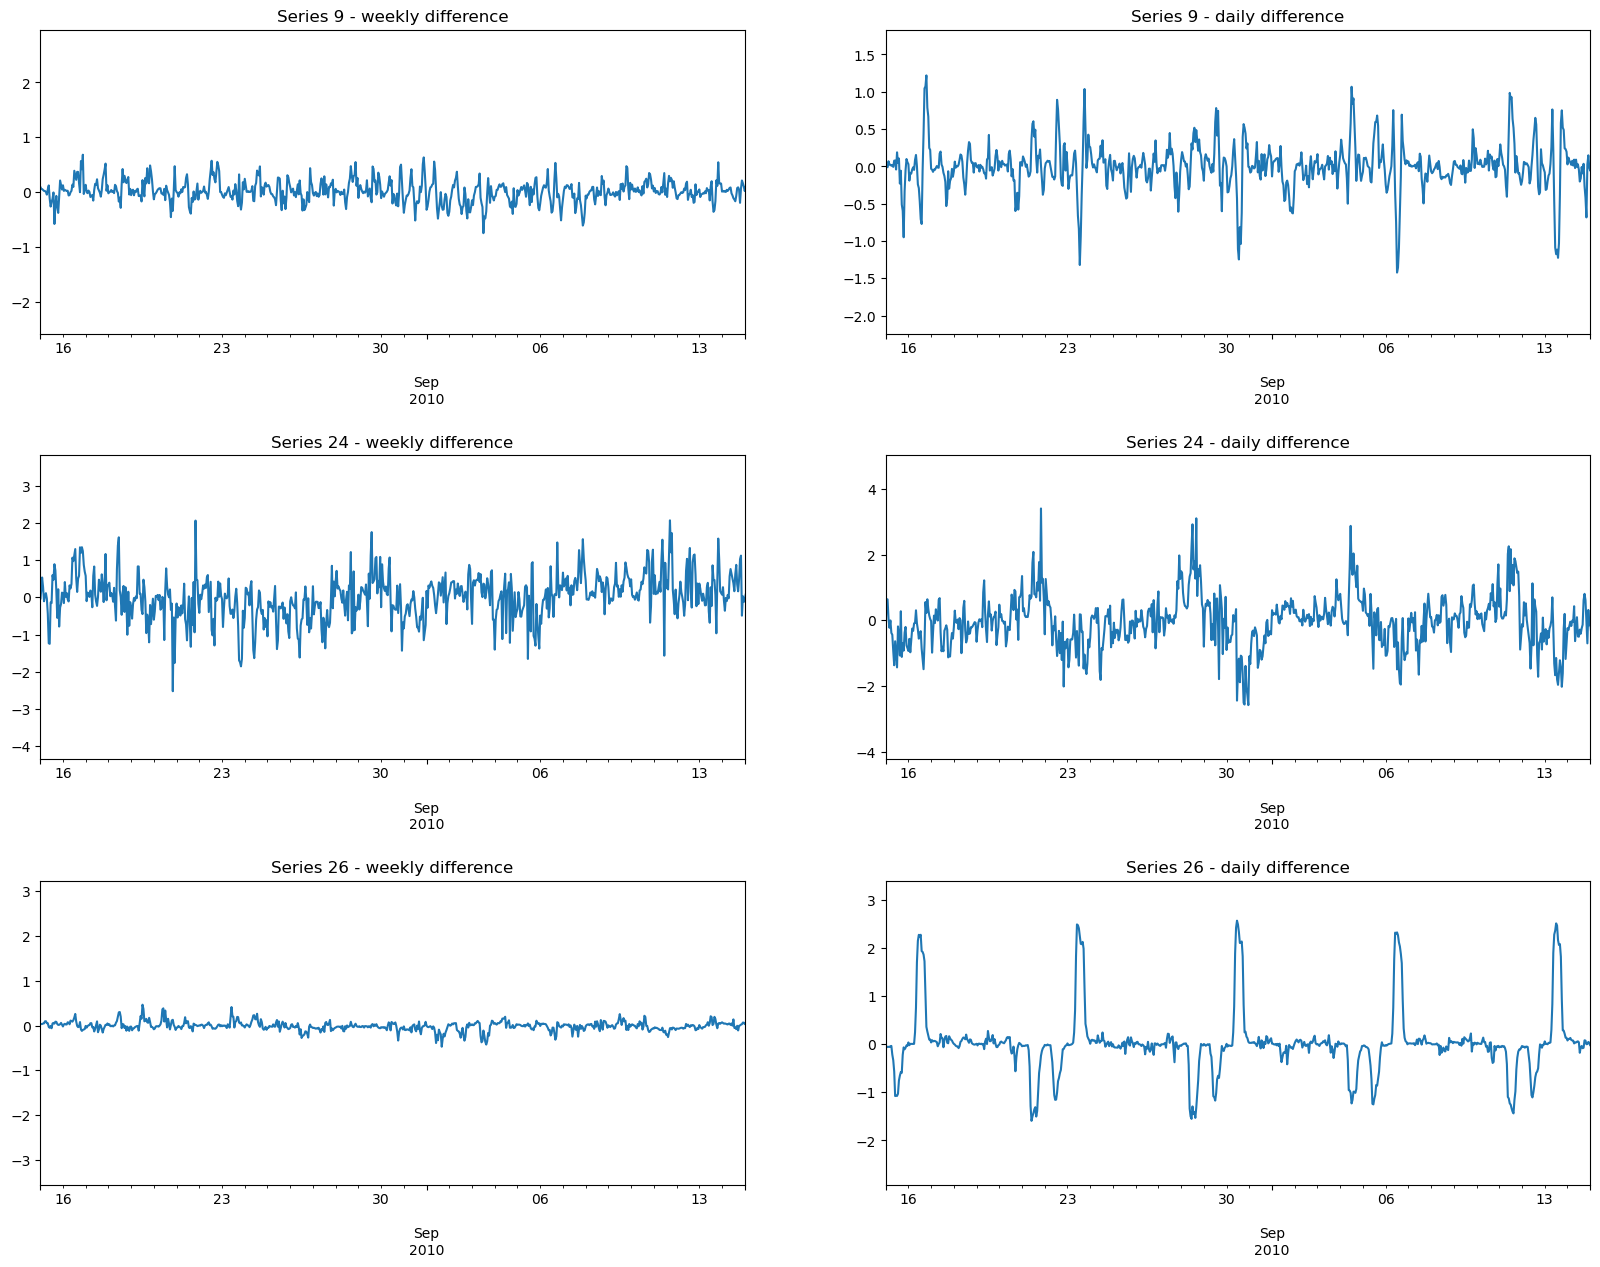

In [33]:
diff_24_series_list = {name: series.diff(24).dropna() for name, series in series_list_monthly.items()}

diff_168_series_list = {name: series.diff(168).dropna() for name, series in series_list_monthly.items()}

fig, axes = plt.subplots(3, 2, figsize=(20, 15))
#fig.suptitle("Series diff", fontsize=16)
fig.subplots_adjust(hspace=0.4, wspace=0.2)

for i, name in enumerate(["9", "24", "26"]):
    diff_168_series_list[name].plot(
        title=f"Series {name} - weekly difference",
        ax=axes[i, 0]
    )
    diff_24_series_list[name].plot(
        title=f"Series {name} - daily difference",
        ax=axes[i, 1]
    )

for ax in axes.flatten():
    ax.tick_params(axis="x", labelrotation=0)
    ax.set_xlim("2010-08-15", "2010-09-15")
    ax.set_xlabel(None)

plt.show()

ADF test - Cluster 9 - 1 day difference: statistic = -17.8349, p-value = 0.0000
ADF test - Cluster 9 - 1 week difference: statistic = -9.7074, p-value = 0.0000
ADF test - Cluster 24 - 1 day difference: statistic = -16.3922, p-value = 0.0000
ADF test - Cluster 24 - 1 week difference: statistic = -9.0671, p-value = 0.0000
ADF test - Cluster 26 - 1 day difference: statistic = -19.3527, p-value = 0.0000
ADF test - Cluster 26 - 1 week difference: statistic = -10.7195, p-value = 0.0000


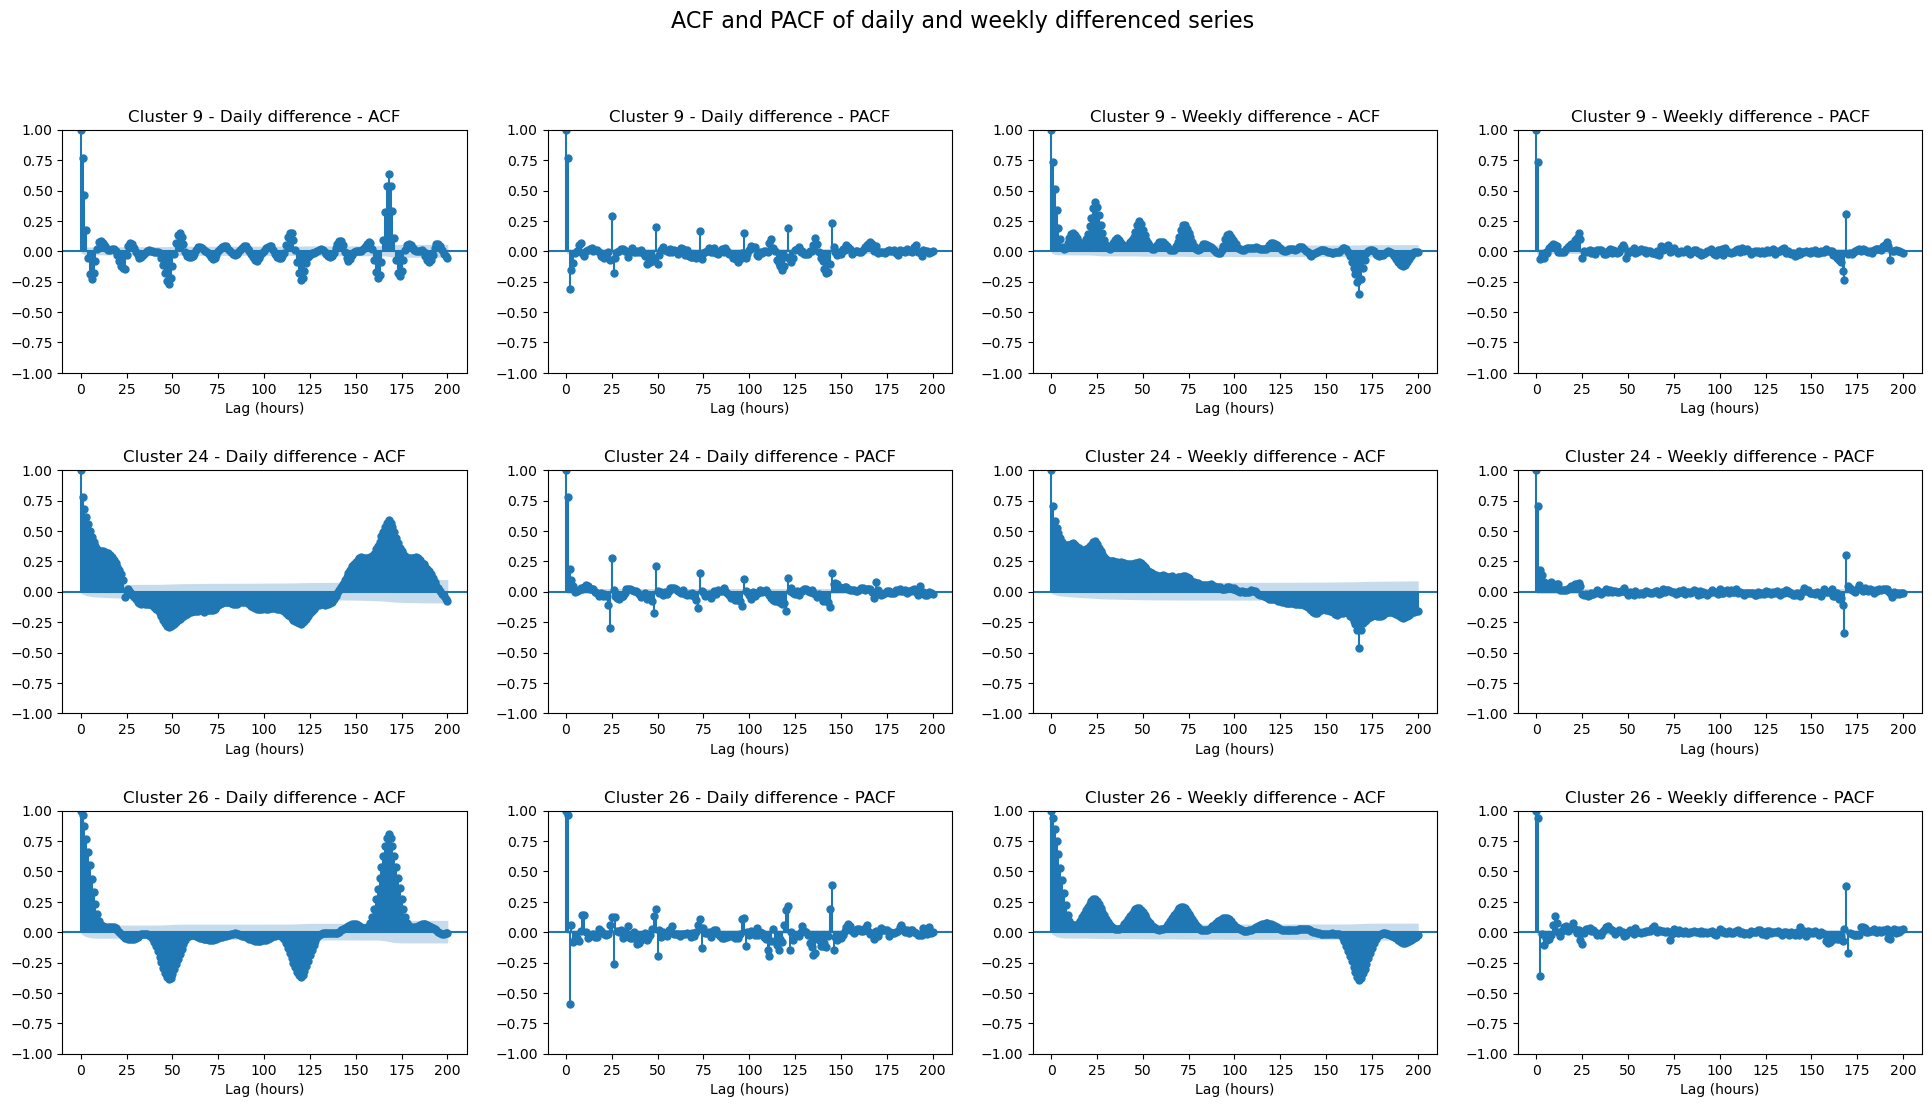

In [34]:
fig, axes = plt.subplots(3, 4, figsize=(24, 12))

fig.suptitle( "ACF and PACF of daily and weekly differenced series", fontsize=16)
fig.subplots_adjust(hspace=.4, wspace=.2)

for i, name in enumerate(diff_24_series_list):
    # Daily difference (lag = 24)
    series_24 = diff_24_series_list[name]
    adf_24 = adfuller(series_24.dropna())
    print(
        f"ADF test - Cluster {name} - 1 day difference: "
        f"statistic = {adf_24[0]:.4f}, "
        f"p-value = {adf_24[1]:.4f}"
    )

    plot_acf(
        series_24.dropna(),
        lags=200,
        ax=axes[i, 0]
    )

    plot_pacf(
        series_24.dropna(),
        lags=200,
        ax=axes[i, 1]
    )

    axes[i, 0].set_title(f"Cluster {name} - Daily difference - ACF")
    axes[i, 1].set_title(f"Cluster {name} - Daily difference - PACF")
    axes[i, 0].set_xlabel("Lag (hours)")
    axes[i, 1].set_xlabel("Lag (hours)")

    # Weekly difference (lag = 168)

    series_168 = diff_168_series_list[name]
    adf_168 = adfuller(series_168.dropna())
    print(
        f"ADF test - Cluster {name} - 1 week difference: "
        f"statistic = {adf_168[0]:.4f}, "
        f"p-value = {adf_168[1]:.4f}"
    )

    plot_acf(
        series_168.dropna(),
        lags=200,
        ax=axes[i, 2]
    )

    plot_pacf(
        series_168.dropna(),
        lags=200,
        ax=axes[i, 3]
    )

    axes[i, 2].set_title(f"Cluster {name} - Weekly difference - ACF")
    axes[i, 3].set_title(f"Cluster {name} - Weekly difference - PACF")
    axes[i, 2].set_xlabel("Lag (hours)")
    axes[i, 3].set_xlabel("Lag (hours)")


plt.show()

After removing weekly and daily periodicity we have significantly reduced the autocorrelation in the series. However, we can still observe from the ACF plots that there is some seasonality that we didn't manage to capture correctly, this is particularly evident in the daily difference series where the weekly autocorrelation is still evident. Moreover from the Dickey Fueller test we can argue that the series are stationary also after the differentiation.


## NEXT WE EXPLORE DIFFERENT FORECASTING MODELS

we start defining a function to evaluate the forecasting, computing Mean Absolute Error, ROot Mean Squared Error, and Mean Absolute Percentage Error

In [35]:
def evaluate_forecast(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

Next we start training some standard SARIMAX models where a SARIMAX(p,d,q)(P,D,Q)_s model, we can write

$$
\Delta y_t =
\underbrace{\mathrm{past\ values}}_{\mathrm{AR}}
+
\underbrace{\mathrm{past\ errors}}_{\mathrm{MA}}
+
\underbrace{\mathrm{seasonal\ past\ values}}_{\mathrm{SAR}}
+
\underbrace{\mathrm{seasonal\ errors}}_{\mathrm{SMA}} +
\underbrace{\beta^\top X_t}_{\mathrm{external\ variables}}+
+
\varepsilon_t
$$

where $y_t$ is a combination of seasonal differentiation and standard differentiation of the series.
In particular:
- $p$ dentoes the number of past terms used for the prediction
- $q$ denotes the number of past errors used for the prediction
- $d$ says how many times the series is differentiated
- $P$ says how many past seasonal terms are used
- $Q$ says how many past seasonal errors are used
- $D$ says how many seasonal differentiantions are considered
- $s$ says what is the periodicity

In [36]:
metrics=dict()  # we use this dict to save the evaluation errors of the different model on the training set.

First we train an AR(1,0,0) model, so without seasonal terms, for each series as baseline

$$y_t=c+\Phi y_{t-1}$$

In [37]:
model_file = "ar1_models.pkl"
# Fit AR(1) on normalized series
ar1_models = {}
ar1_forecasts = {}
metrics["ar1_monthly_normalized"] = {}

execute=False
if execute:
    for name, train_normalized in series_list_monthly.items():
        name = str(name)
        model = ARIMA(train_normalized, order=(1, 0, 0), trend="c")
        ar1_models[name] = model.fit()

    with open(model_file, "wb") as f:
        pickle.dump(ar1_models, f)

Cluster 9, AR(1): MAE=0.5886, RMSE=0.6789, MAPE=71.87%
Cluster 24, AR(1): MAE=0.3264, RMSE=0.3893, MAPE=71.49%
Cluster 26, AR(1): MAE=4.3737, RMSE=5.2565, MAPE=69.65%


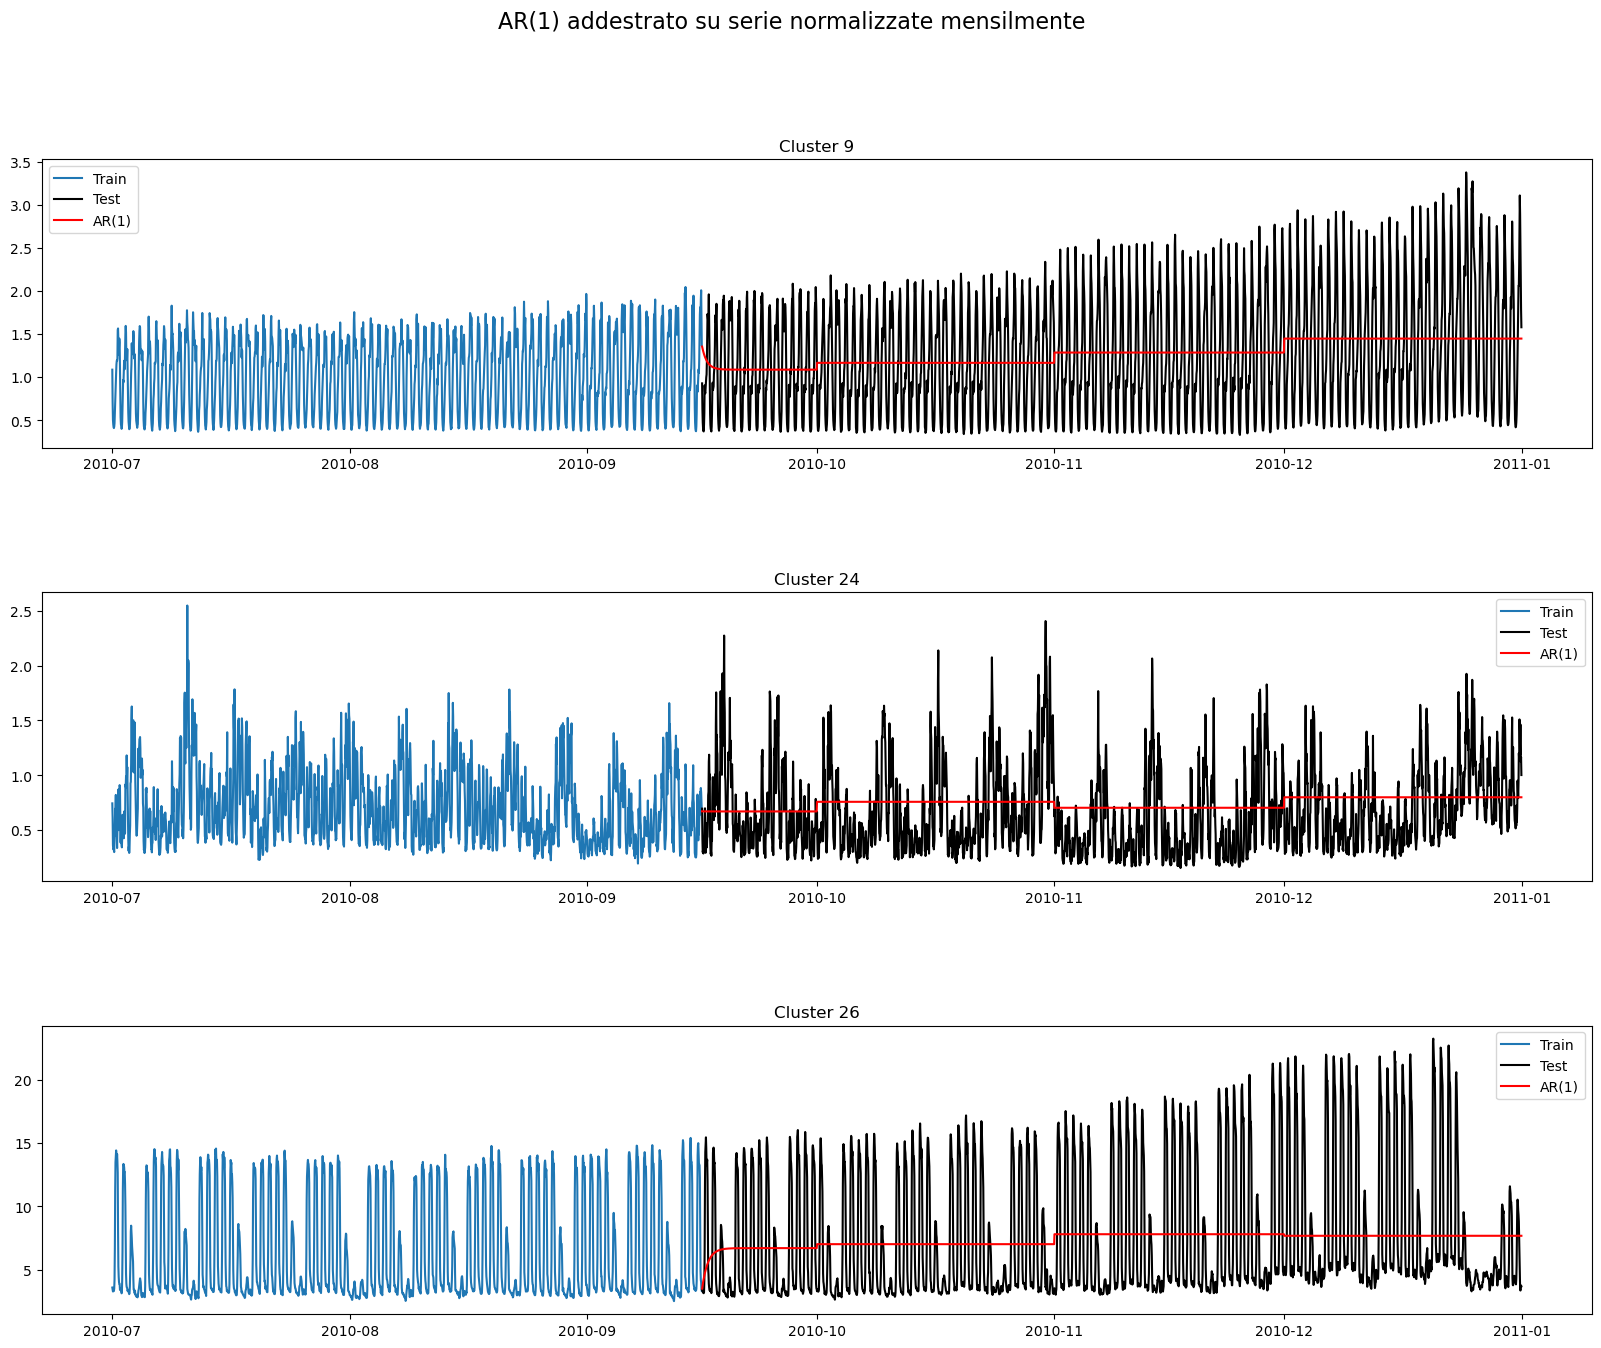

In [38]:
# Import monthly statistics from CSV and transorm in a dictionary
stats_df = pd.read_csv("monthly_stats_by_series.csv")
monthly_stats = {}

for _, row in stats_df.iterrows():
    stats_name = str(int(float(row["series"])))
    month = int(row["month"])
    monthly_stats.setdefault(stats_name, {})
    monthly_stats[stats_name][month] = {
        "mean": float(row["mean"]),
        "std": float(row["std"]),
    }

# Import AR1 models from pickle
with open("ar1_models.pkl", "rb") as f:
    ar1_models = pickle.load(f)

# Make forecasting
ar1_forecasts = {}
metrics["ar1"] = {}

for name, test_series in series_list_test.items():
    model_name = str(name)
    stats_name = str(int(float(name)))
    forecast_normalized = ar1_models[model_name].get_forecast(steps=len(test_series)).predicted_mean
    forecast_original_scale = inverse_monthly(forecast_normalized, monthly_stats[stats_name]) #apply inverse standarditation
    ar1_forecasts[model_name] = forecast_original_scale

    # compute and save evaluation metrics on the test dataset
    mae, rmse, mape = evaluate_forecast(test_series, forecast_original_scale)
    metrics["ar1"][model_name] = {
        "mae": mae,
        "rmse": rmse,
        "mape": mape}

    print(
        f"Cluster {model_name}, AR(1): "
        f"MAE={mae:.4f}, RMSE={rmse:.4f}, MAPE={mape:.2f}%"
    )

# Plot forecasts again true values
fig, axes = plt.subplots(3, 1, figsize=(20, 15))
fig.suptitle("AR(1) addestrato su serie normalizzate mensilmente", fontsize=16)
fig.subplots_adjust(hspace=0.5)

for i, (name, train_series) in enumerate(series_list.items()):
    model_name = str(name)
    test_series = series_list_test[name]
    forecast = ar1_forecasts[model_name]

    axes[i].plot(train_series.loc["2010-07-01":], label="Train")
    axes[i].plot(test_series, label="Test", color="black")
    axes[i].plot(
        forecast.index,
        forecast,
        label="AR(1)",
        color="red",
    )
    axes[i].set_title(f"Cluster {model_name}")
    axes[i].legend()

plt.show()

Next we consider SARIMAX models that only include seasonal terms with seasonl window of 1 day, indeed the series don't have any trend. On the other hand, to correctly capture certain patterns we should include seasonal terms relative to a window of 1 week or longer. However the training the computational cost to fit a SARIMA model with long dependecies increase and so we leave the correction of longer periodicities to the external features. The expression of the trained model is:

$$y_t = c+(1+\Phi_1)y_{t-24}-\Phi_1 y_{t-48}+\varepsilon_t$$


In [39]:
sarima_models = {}
# Fit SARIMAX(0,0,0)(1,1,0,24) models on normalized series
order = (0, 0, 0)
seasonal_order = (1, 1, 0, 24)
model_file = f"sarimax_monthly_normalized_{order}_{seasonal_order}.pkl"

execute=False
if execute:
  for name, series in series_list_monthly.items():
      model = SARIMAX(
          series,
          order=order,
          seasonal_order=seasonal_order,
          trend="c",
      )
      sarima_models[name] = model.fit(low_memory=True)

  with open(model_file, "wb") as f:
      pickle.dump(sarima_models, f)


Series 9:                                 SARIMAX Results                                 
Dep. Variable:                cluster_9   No. Observations:                10272
Model:             SARIMAX(1, 1, 0, 24)   Log Likelihood               -1613.845
Date:                  Tue, 13 Oct 2026   AIC                           3241.691
Time:                          20:00:18   BIC                           3292.335
Sample:                      07-15-2009   HQIC                          3258.813
                           - 09-15-2010                                         
Covariance Type:                 approx                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0006      0.003      0.206      0.837      -0.005       0.006
day_type       0.0819      0.003     26.304      0.000       0.076       0.088
is_holiday     0.1225     

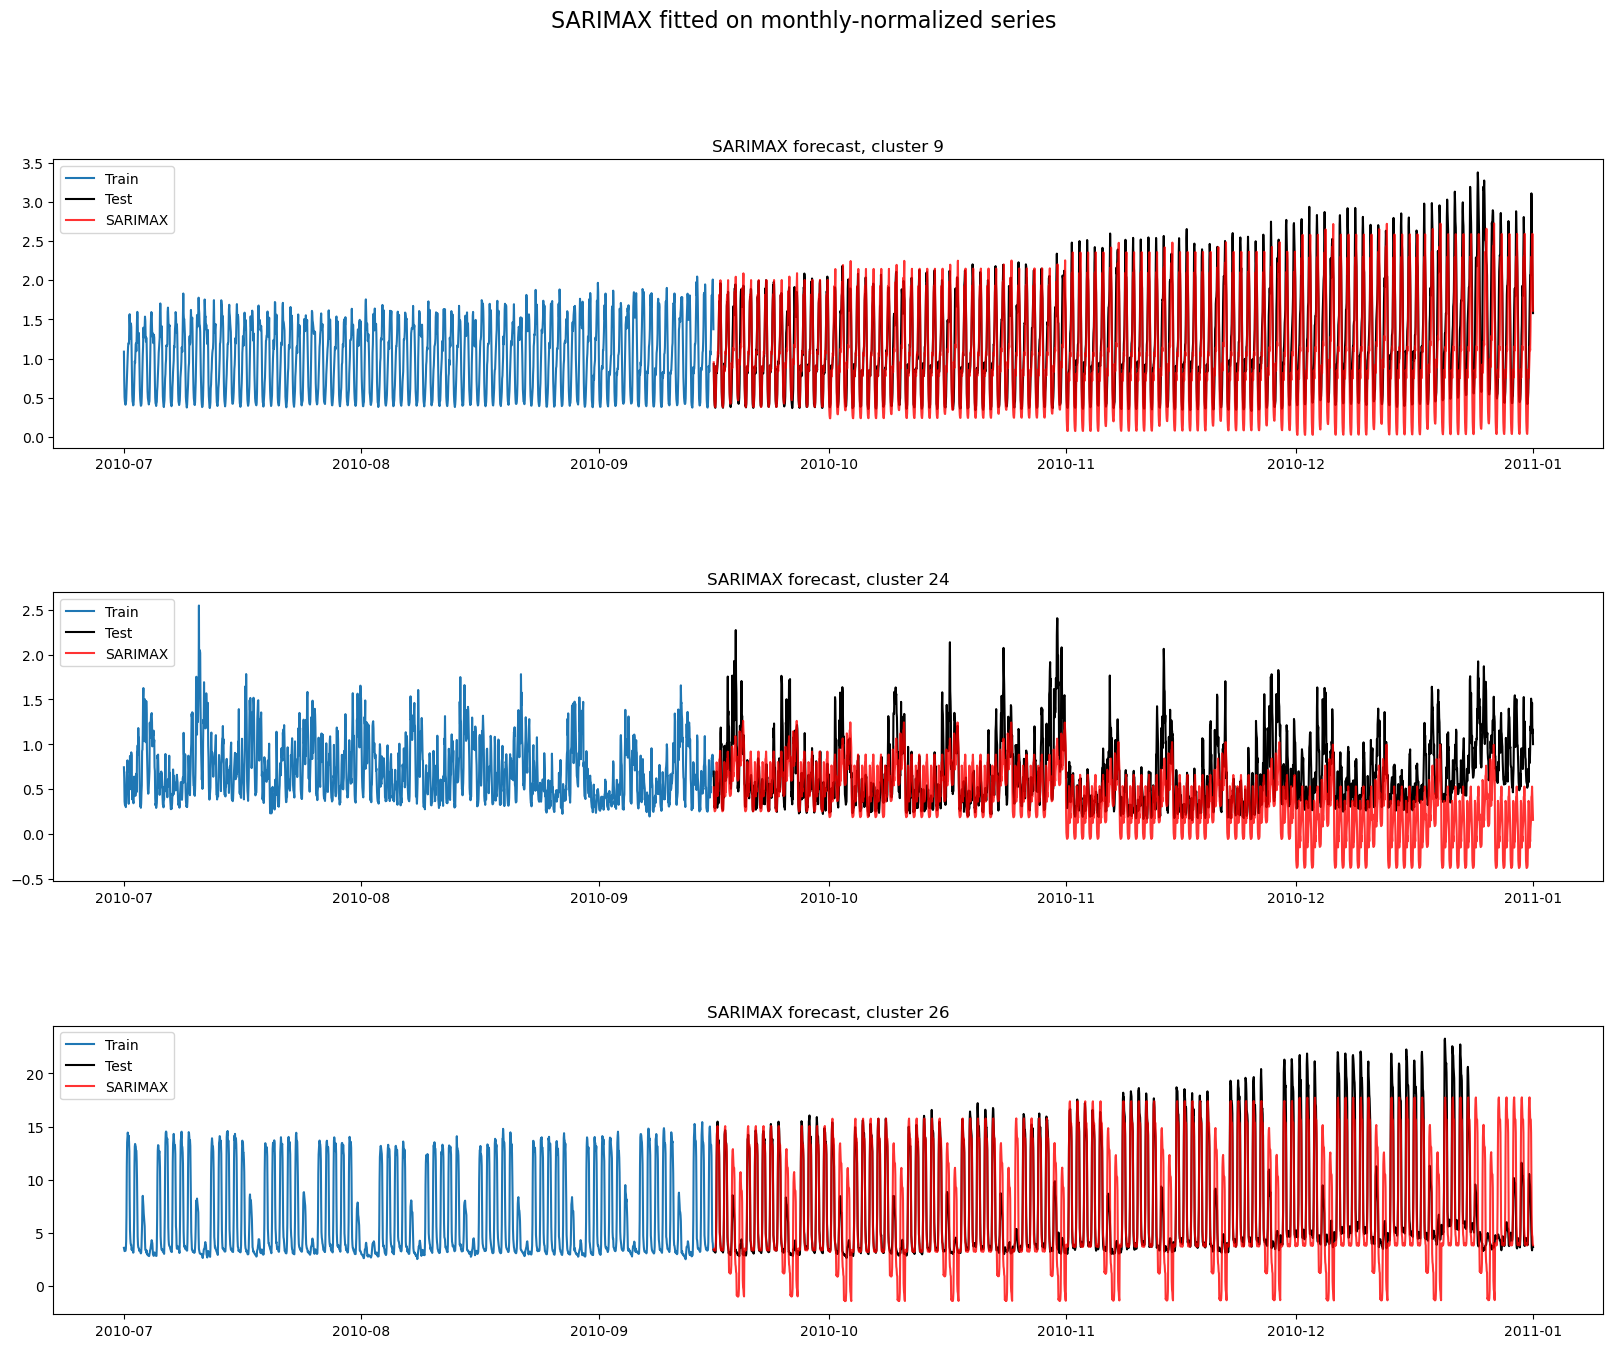

In [40]:
# Upload models
with open(model_file, "rb") as f:
    sarima_models_only_seasonal = pickle.load(f)

# Import monthly statistics from CSV and transorm in a dictionary
stats_df = pd.read_csv("monthly_stats_by_series.csv")
monthly_stats = {}
for _, row in stats_df.iterrows():
    stats_name = str(int(float(row["series"])))
    month = int(row["month"])
    monthly_stats.setdefault(stats_name, {})
    monthly_stats[stats_name][month] = {
        "mean": float(row["mean"]),
        "std": float(row["std"])}

# print model summary
for name, model in sarima_models_only_seasonal.items():
    print(f"Series {name}: {model.summary()}")

metrics[f"sarimax_{order}_{seasonal_order}"] = {}
sarima_forecasts = {}

fig, axes = plt.subplots(3, 1, figsize=(20, 15))
fig.suptitle("SARIMAX fitted on monthly-normalized series", fontsize=16)
fig.subplots_adjust(hspace=0.5)


for i, (name, test_series) in enumerate(series_list_test.items()):
    name = str(name)
    stats_name = str(int(float(name)))

    # make predictions
    forecast_normalized = sarima_models_only_seasonal[name].get_forecast(steps=len(test_series), exog=Ftr_test).predicted_mean
    predicted_mean = inverse_monthly(forecast_normalized, monthly_stats[stats_name])
    sarima_forecasts[name] = predicted_mean

    # evaluate metrics on test set
    mae, rmse, mape = evaluate_forecast(test_series, predicted_mean)
    metrics[f"sarimax_{order}_{seasonal_order}"][name] = {
        "mae": mae,
        "rmse": rmse,
        "mape": mape}

    print(f"Series {name}, SARIMAX {order} x {seasonal_order}: "
        f"MAE={mae:.4f}, RMSE={rmse:.4f}, MAPE={mape:.2f}%")

    # display predicitions against true values
    axes[i].plot(series_list[name].loc["2010-07-01":], label="Train")
    axes[i].plot(test_series, label="Test", color="black")
    axes[i].plot(
        predicted_mean.index,
        predicted_mean,
        label="SARIMAX",
        color="red",
        alpha=0.8,
    )
    axes[i].set_title(f"SARIMAX forecast, cluster {name}")
    axes[i].legend()

plt.show()

From the last fit we obsere different problems, first the models struggled to capture the weekly seasonality because the features are only considered additively while they clearly have a multiplicative effect on the energy consumption. Second as we can also see from the p-values of the month-features terms and holiday-feature term, the fits didn't capture correctly the annual pattern or the effect of holidays on the energy consumption.

In [ ]:
sarima_models = {}
order = (0, 0, 0)
seasonal_order = (1, 1, 0, 168)
model_file = f"sarimax_monthly_simplediff_{order}_{seasonal_order}.pkl"
execute=True

if execute:
    # FIT THE MODELS
    for name, series in series_list_monthly.items():

        model = SARIMAX(series,
                        order=order,
                        seasonal_order=seasonal_order,
                        simple_differencing=True) # the model is fitted only on the differentiated series to reduce computational time

        sarima_models[str(name)] = model.fit(maxiter=50, disp=False, low_memory=True)

        print(f"Cluster {name}: convergence = "
            f"{sarima_models[str(name)].mle_retvals.get('converged', 'n/d')}")

    with open(model_file, "wb") as f:
        pickle.dump(sarima_models, f)

Cluster 9: convergence = True
Cluster 24: convergence = True
Cluster 26: convergence = True


Series 9:                                       SARIMAX Results                                      
Dep. Variable:                     DS168.cluster_9   No. Observations:                10104
Model:             SARIMAX(2, 0, 0)x(1, 0, 0, 168)   Log Likelihood                5409.009
Date:                             Wed, 14 Oct 2026   AIC                         -10810.017
Time:                                     09:46:11   BIC                         -10781.134
Sample:                                 07-22-2009   HQIC                        -10800.246
                                      - 09-15-2010                                         
Covariance Type:                            approx                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8098      0.010     81.484      0.000       0.790       0.829
ar.L2         -0.

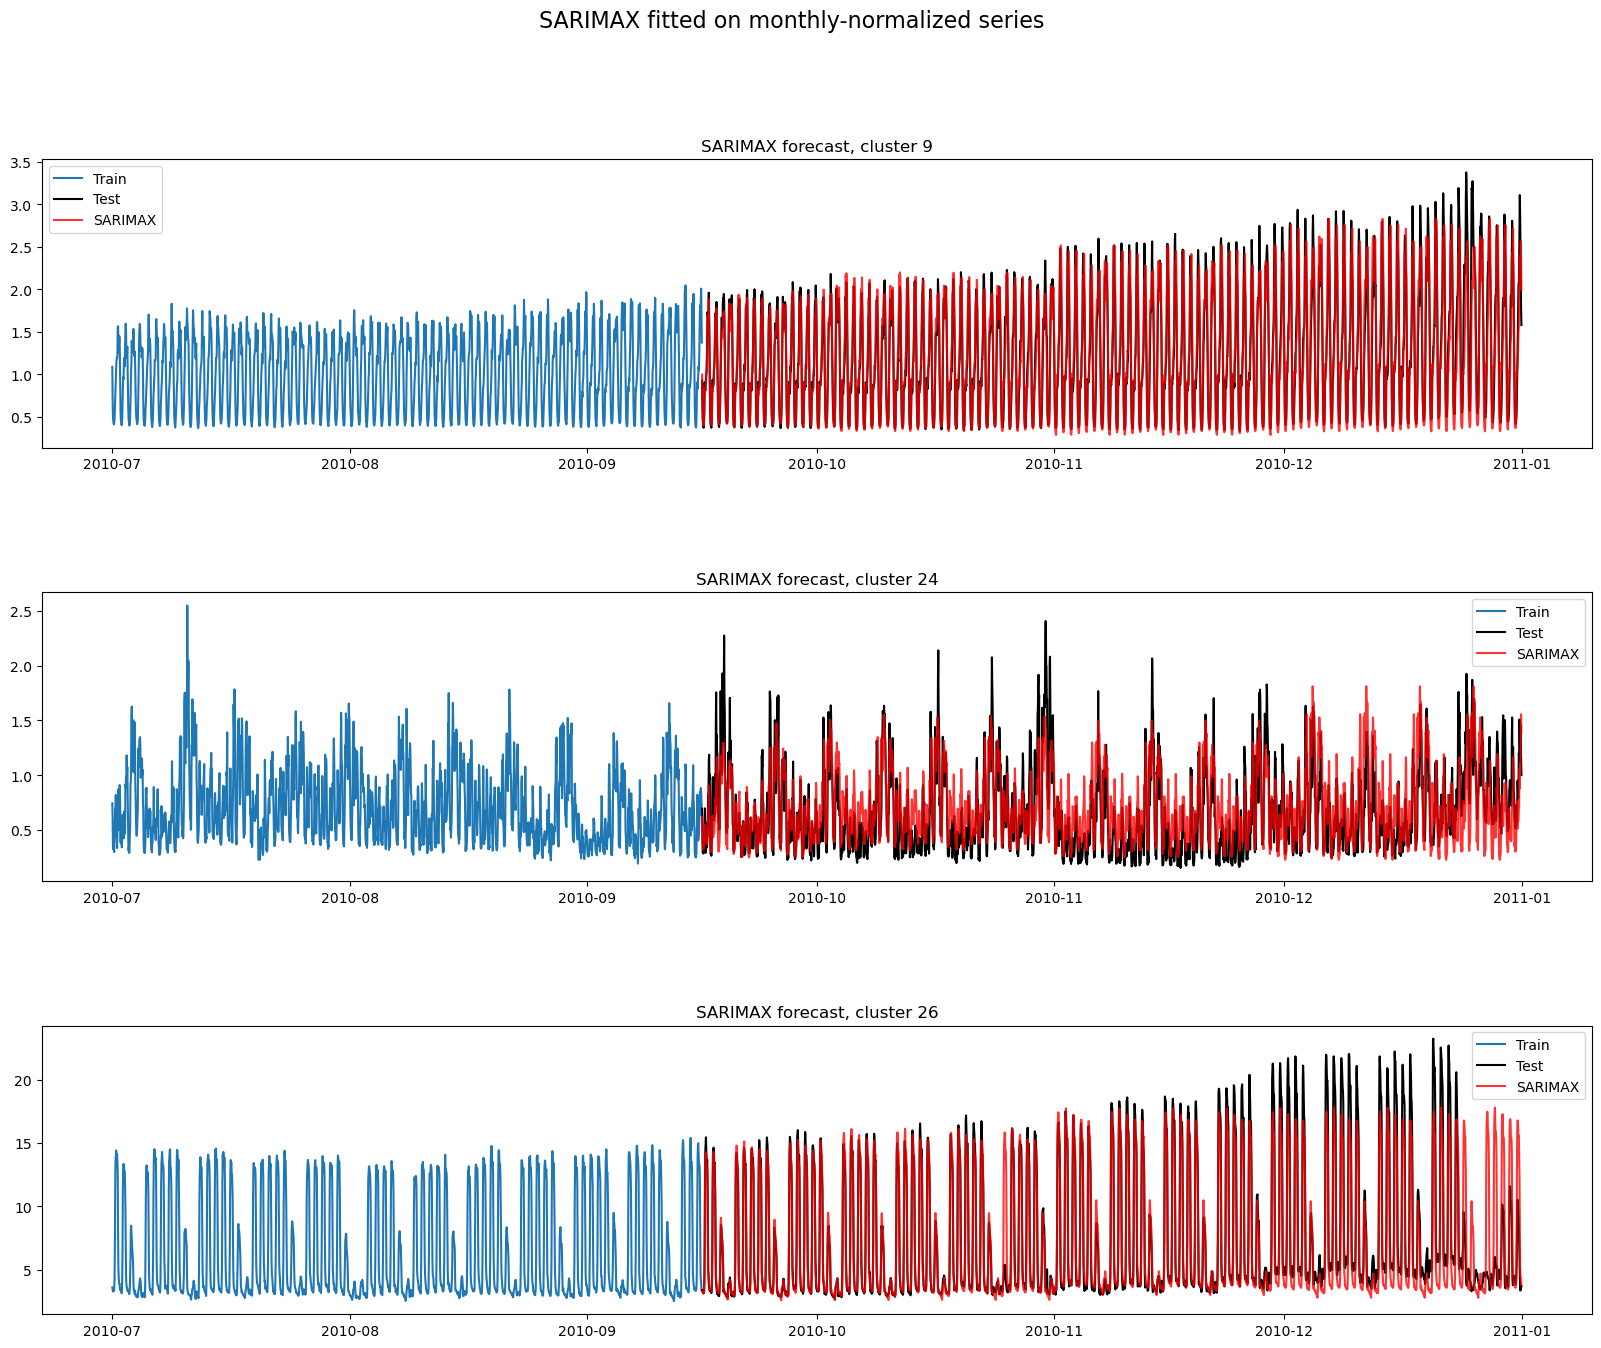

In [52]:
# Upload models
with open(model_file, "rb") as f:
    sarima_models_only_seasonal = pickle.load(f)

# Import monthly statistics from CSV and transform in a dictionary
stats_df = pd.read_csv("monthly_stats_by_series.csv")
monthly_stats = {}
for _, row in stats_df.iterrows():
    stats_name = str(int(float(row["series"])))
    month = int(row["month"])
    monthly_stats.setdefault(stats_name, {})
    monthly_stats[stats_name][month] = {
        "mean": float(row["mean"]),
        "std": float(row["std"]),
    }

# Print model summary
for name, model in sarima_models_only_seasonal.items():
    print(f"Series {name}: {model.summary()}")

metrics[f"sarimax_{order}_{seasonal_order}"] = {}
sarima_forecasts = {}

fig, axes = plt.subplots(3, 1, figsize=(20, 15))
fig.suptitle("SARIMAX fitted on monthly-normalized series", fontsize=16)
fig.subplots_adjust(hspace=0.5)

seasonal_period = seasonal_order[3]

for i, (name, test_series) in enumerate(series_list_test.items()):
    name = str(name)
    stats_name = str(int(float(name)))

    # Forecast on differentiated series
    forecast_diff = sarima_models_only_seasonal[name].get_forecast(
        steps=len(test_series),
#        exog=Ftr_test,
    ).predicted_mean

    # Rebuild non differentiated series
    history = list(series_list_monthly[name].to_numpy())
    forecast_normalized_values = []

    for diff_value in forecast_diff.to_numpy():
        value = diff_value + history[-seasonal_period]
        forecast_normalized_values.append(value)
        history.append(value)

    forecast_normalized = pd.Series(
        forecast_normalized_values,
        index=test_series.index,
        name=name)

    # Remove standarditation
    predicted_mean = inverse_monthly(
        forecast_normalized,
        monthly_stats[stats_name],
    )
    sarima_forecasts[name] = predicted_mean

    # Evaluate metrics on test set
    mae, rmse, mape = evaluate_forecast(test_series, predicted_mean)
    metrics[f"sarimax_{order}_{seasonal_order}"][name] = {
        "mae": mae,
        "rmse": rmse,
        "mape": mape,
    }

    print(
        f"Series {name}, SARIMAX {order} x {seasonal_order}: "
        f"MAE={mae:.4f}, RMSE={rmse:.4f}, MAPE={mape:.2f}%"
    )

    # Display predictions against true values
    axes[i].plot(
        series_list[name].loc["2010-07-01":],
        label="Train",
    )
    axes[i].plot(test_series, label="Test", color="black")
    axes[i].plot(
        predicted_mean.index,
        predicted_mean,
        label="SARIMAX",
        color="red",
        alpha=0.8,
    )
    axes[i].set_title(f"SARIMAX forecast, cluster {name}")
    axes[i].legend()

plt.show()

# RECURRENT DEEP LEARNIN MODELS

Next we test some recurrent model, in particular we consider an LSTM model

First we preprocess the series, scaling them between 0 and 1.

In [41]:
# Scale each time series to the [0, 1] range using MinMaxScaler and store the scaler in a dict.
scaled_series_list = {} # scaled training series
scaled_series_list_test = {}  # scaled test series
scalers={} # dict of fitted scalers

for name,series in series_list.items():
    scaler=MinMaxScaler()
    scaled_series_list[name]=scaler.fit_transform(series.to_frame())
    scalers[name] = scaler
    scaled_series_list_test[name] = scaler.transform(series_list_test[name].to_frame())


Second, we assume that we want to predict the energy consumption over the next (M) hours, given the energy consumption observed during the previous (P) hours.

We therefore construct the training dataset for the LSTM model by considering sequences of (P) consecutive energy consumption values as input and the following (M) consecutive values as the prediction target.

In [43]:
def create_sequences(serie, window_size, M):
    """
    Create input-output sequences for training and testing LSTM model.

    Parameters
    ----------
    serie : Time series data.
    window_size (P) : Number of past observations used as input.
    M : Number of future observations to predict.

    Returns
    -------
    X : np.ndarray
        Input sequences of shape (samples, window_size, ...).
    y : np.ndarray
        Target sequences
    """

    X = []
    y = []

    for i in range(len(serie) - window_size - M + 1):
        X.append(serie[i:i+window_size])
        y.append(serie[i+window_size:i+window_size+M])

    return np.array(X), np.array(y).squeeze(-1)

Next we write a function to iteratively predict n-forecasting values starting from the last window of training values and a model that generates M<n values at a time

In [ ]:
def lstm_predict_n(model, n, starting_X, M):
    """"
    model - trained model used for make predictions
    n - number of predictions to make
    starting_X batch of data of the dimension of input of model
    m - number of predictions made by the model
    """
    
    X = starting_X.copy()
    y = X.flatten().tolist()
    n_pred = 0

    while n_pred < n:
        X_inp = X.reshape(1, X.shape[0], X.shape[1])
        next_values = model.predict(X_inp, verbose=0).flatten() # predict new values
        remaining = n - n_pred
        next_values = next_values[:remaining] # consider less values than predicted if n was exceeeded
        y.extend(next_values.tolist()) #add predictions to output
        X = np.vstack([X[len(next_values):], next_values.reshape(-1, 1)]) #discard first M values of X and add the generated M
        n_pred += len(next_values)
    return y

Next we consider an LSTM model that uses as features only the data relative to the energy consuption

In [51]:
lstm_models = {}
window_size=168
X_train_dict={}
X_test_dict={}
y_train_dict={}
y_test_dict={}
M=24
execute=False


for name,series in scaled_series_list.items():
    # We create train and test set using the function create_sequences
    X_train, y_train = create_sequences(series, window_size, M) 
    X_test, y_test = create_sequences(scaled_series_list_test[name], window_size, M)
    X_train_dict[name]=X_train
    X_test_dict[name]=X_test
    y_train_dict[name]=y_train
    y_test_dict[name]=y_test

    if execute:
        # We consider a simple lstm model that takes in input a training data of window_size measurments 
        # and applies an LSTM layer with 32 units and an output layer with M-units (where M is the number of predictions we want) 
        lstm = Sequential([Input(shape=(window_size, 1)),
                        LSTM(32, activation="tanh"),
                        Dense(M)])

        early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

        lstm.compile(optimizer="adam", loss="mse")
        lstm.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, callbacks=[early_stop], verbose=0)
        lstm_models[name]=lstm

if execute:
    with open("lstm_models.pkl", "wb") as f:
        pickle.dump(lstm_models, f)

Cluster 9, direct rolling (24-hour horizon):MAE=0.1246, RMSE=0.1783, MAPE=10.90%
Cluster 9, recursive forecast: MAE=0.3843, RMSE=0.5184, MAPE=31.18%
Cluster 24, direct rolling (24-hour horizon):MAE=0.1519, RMSE=0.2067, MAPE=27.67%
Cluster 24, recursive forecast: MAE=0.2728, RMSE=0.3436, MAPE=59.44%
Cluster 26, direct rolling (24-hour horizon):MAE=0.8211, RMSE=1.4022, MAPE=13.06%
Cluster 26, recursive forecast: MAE=2.9065, RMSE=4.3105, MAPE=36.05%


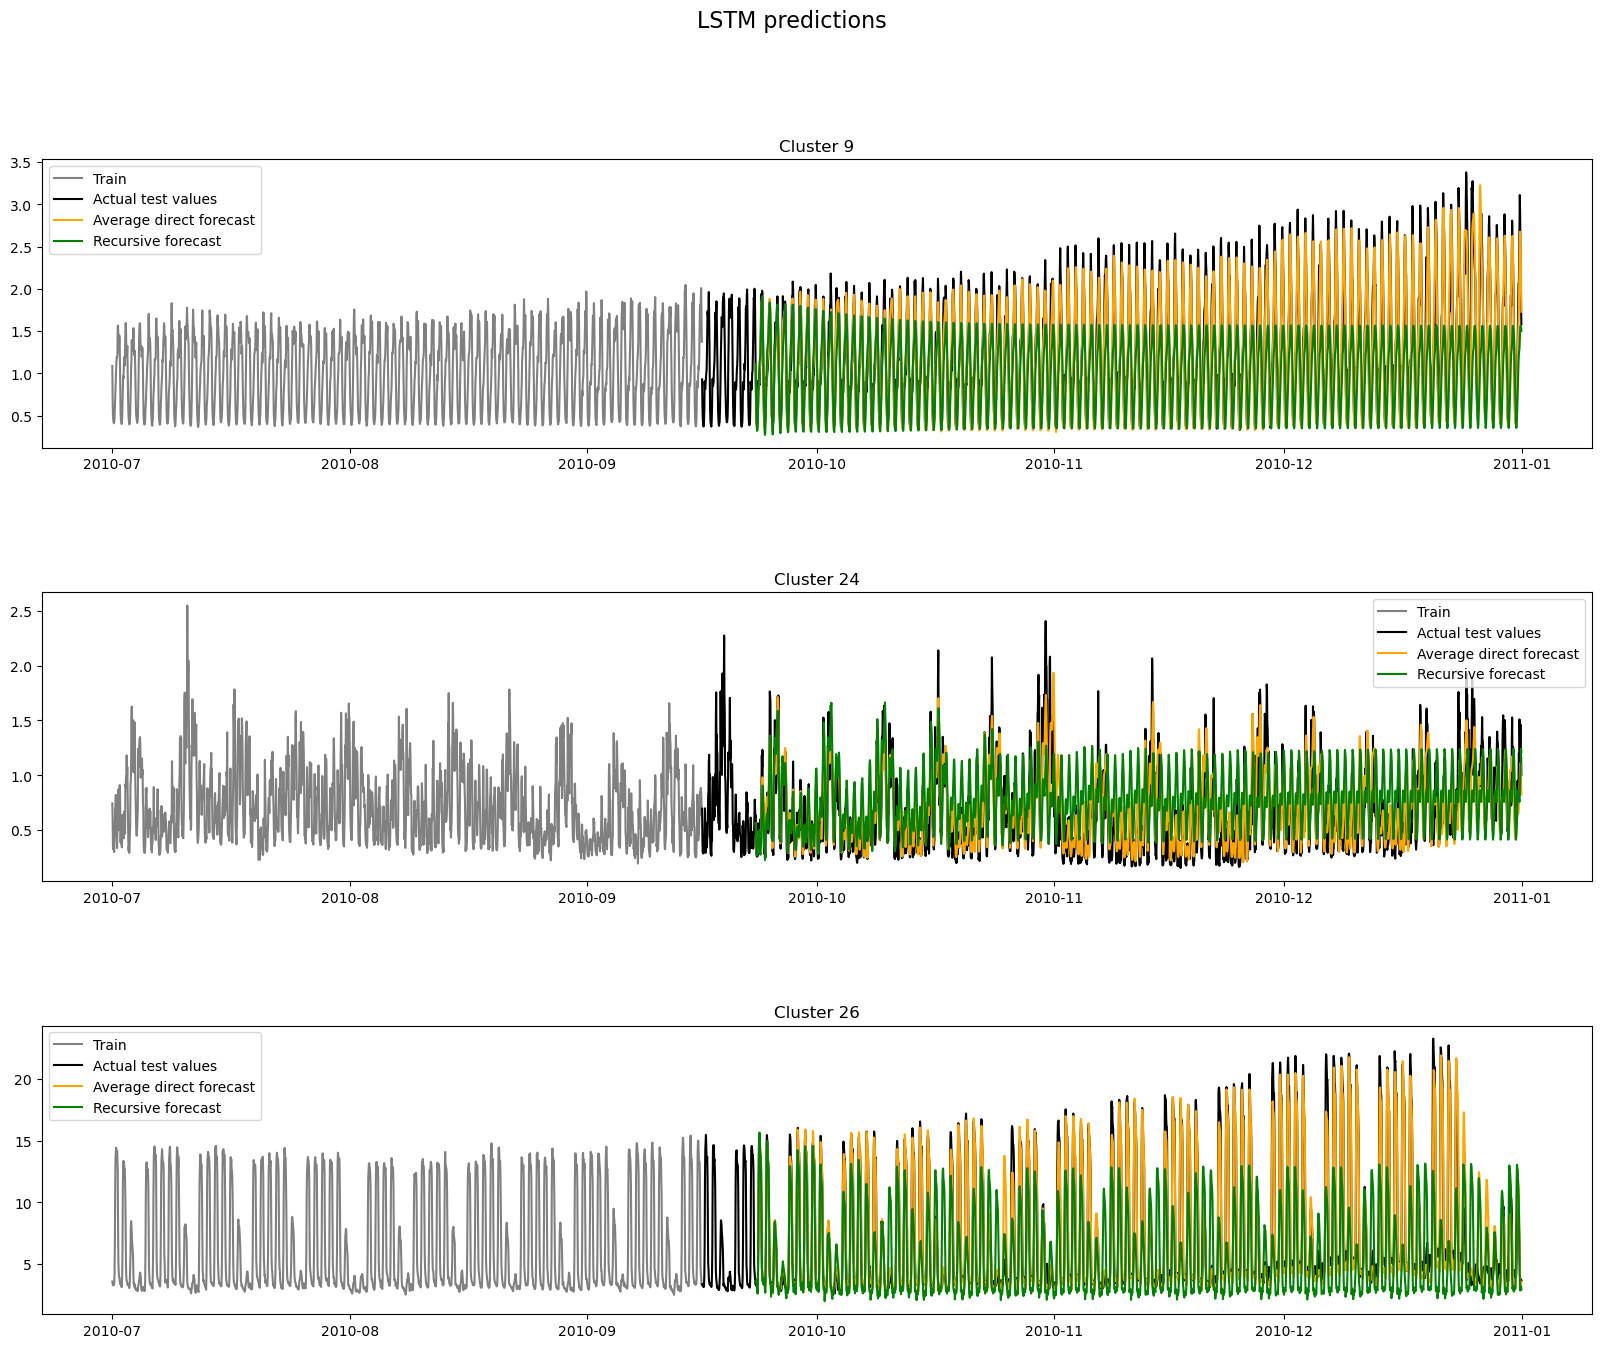

In [62]:
# Load the trained LSTM models
with open("lstm_models.pkl", "rb") as f:
    lstm_models = pickle.load(f)

rolling_key = f"lstm_direct_M{M}"
mean_timestamp_key = f"lstm_direct_mean_by_timestamp_M{M}"
recursive_key = f"lstm_recursive_M{M}"

# Keep metrics from previously evaluated models
metrics.setdefault(rolling_key, {})
metrics.setdefault(mean_timestamp_key, {})
metrics.setdefault(recursive_key, {})

fig, axes = plt.subplots(3, 1, figsize=(20, 15))
fig.suptitle("LSTM predictions", fontsize=16)
fig.subplots_adjust(hspace=0.5)

for i, (name, train_series) in enumerate(series_list.items()):
    name = str(name)
    model = lstm_models[name]
    test_series = series_list_test[name]

    # Predict M future values for every hourly test window
    predictions = model.predict(X_test_dict[name], verbose=0)
    y_true_scaled = y_test_dict[name]

    # Convert predictions and targets back to the original scale
    y_pred_multi = scalers[name].inverse_transform(predictions.reshape(-1, 1)).reshape(predictions.shape)
    y_true_multi = scalers[name].inverse_transform(y_true_scaled.reshape(-1, 1)).reshape(y_true_scaled.shape)

    # compare predicted values with actual ones 
    mae_rolling, rmse_rolling, mape_rolling = evaluate_forecast(y_true_multi.ravel(), y_pred_multi.ravel())

    metrics[rolling_key][name] = {
        "mae": mae_rolling,
        "rmse": rmse_rolling,
        "mape": mape_rolling,
    }

    print(f"Cluster {name}, direct rolling ({M}-hour horizon):"  
          f"MAE={mae_rolling:.4f}, RMSE={rmse_rolling:.4f}, "  f"MAPE={mape_rolling:.2f}%")

    # Note that each time consumption is predicted multiple time: there are M sequences that have it in the predictions 
    # So next we average all the predictions of the same time-day consumption forecasting to make a plot
    prediction_sum = np.zeros(len(test_series))
    prediction_count = np.zeros(len(test_series), dtype=int)

    for origin in range(len(y_pred_multi)):
        start = window_size + origin
        end = start + M
        prediction_sum[start:end] += y_pred_multi[origin]
        prediction_count[start:end] += 1

    valid_positions = np.flatnonzero(prediction_count > 0)
    direct_mean_values = (prediction_sum[valid_positions] / prediction_count[valid_positions])
    direct_index = test_series.index[valid_positions]
    direct_actual = test_series.iloc[valid_positions]

    # Generate a recursive forecast of all the test period from the first test input window
    n_recursive = len(test_series) - window_size
    y_recursive_scaled_with_window = lstm_predict_n(model, n_recursive, X_test_dict[name][0], M)

    # Convert to the original scale and remove the initial input window
    y_recursive_full = scalers[name].inverse_transform(np.asarray(y_recursive_scaled_with_window).reshape(-1, 1)).flatten()
    y_recursive = y_recursive_full[window_size : window_size + n_recursive]
    recursive_index = test_series.index[window_size : window_size + n_recursive]
    recursive_actual = test_series.iloc[window_size : window_size + n_recursive]

    # Score the recursive forecast over its predicted timestamps
    mae_recursive, rmse_recursive, mape_recursive = evaluate_forecast(recursive_actual, y_recursive)

    metrics[recursive_key][name] = {"mae": mae_recursive,
                                    "rmse": rmse_recursive,
                                    "mape": mape_recursive}

    print(f"Cluster {name}, recursive forecast: "
          f"MAE={mae_recursive:.4f}, RMSE={rmse_recursive:.4f}, "
          f"MAPE={mape_recursive:.2f}%")

    # Plot actual values and forecasts
    axes[i].plot(train_series.loc["2010-07-01":],
                label="Train",
                color="gray")
    
    axes[i].plot(test_series,
                label="Actual test values",
                color="black")
    
    axes[i].plot(direct_index,
                direct_mean_values,
                label=f"Average direct forecast",
                color="orange")
    
    axes[i].plot(recursive_index,
                y_recursive,
                label="Recursive forecast",
                color="green")
    
    axes[i].set_title(f"Cluster {name}")
    axes[i].legend()

plt.show()



### DISPLAY THE FORECASTING PERFORMANCE OF EACH MODEL ON THE THREE TIME SERIES 
(IN BOLD THE BEST MODEL)

In [77]:
from IPython.display import display, Markdown, HTML
from html import escape

metric_columns = ["MAE", "RMSE", "MAPE"]

cluster_names = sorted({
    cluster_name
    for cluster_results in metrics.values()
    if isinstance(cluster_results, dict)
    for cluster_name in cluster_results
}, key=str)

for cluster_name in cluster_names:
    rows = []

    for model_name, cluster_results in metrics.items():
        if not isinstance(cluster_results, dict):
            continue

        scores = cluster_results.get(cluster_name)
        if isinstance(scores, dict):
            rows.append({
                "Model": model_name,
                "MAE": scores.get("mae"),
                "RMSE": scores.get("rmse"),
                "MAPE": scores.get("mape"),
            })

    if not rows:
        continue

    table = pd.DataFrame(rows).set_index("Model")
    display(Markdown(f"### Cluster {cluster_name}"))

    html = """
    <table style="border-collapse: collapse;">
      <thead>
        <tr>
          <th style="padding: 6px; text-align: left;">Model</th>
          <th style="padding: 6px;">MAE</th>
          <th style="padding: 6px;">RMSE</th>
          <th style="padding: 6px;">MAPE</th>
        </tr>
      </thead>
      <tbody>
    """

    for model_name, row in table.iterrows():
        html += f"<tr><td style='padding: 6px'>{escape(str(model_name))}</td>"

        for column in metric_columns:
            value = row[column]
            minimum = table[column].min()

            if pd.isna(value):
                text = "—"
            else:
                text = f"{value:.4f}"
                if pd.notna(minimum) and value == minimum:
                    text = f"<strong>{text}</strong>"

            html += f"<td style='padding: 6px; text-align: right'>{text}</td>"

        html += "</tr>"

    html += "</tbody></table>"
    display(HTML(html))

### Cluster 24

Model,MAE,RMSE,MAPE
lstm_direct_M24,0.1519,0.2067,27.6698
lstm_recursive_M24,0.2728,0.3436,59.4399
ar1,0.3264,0.3893,71.4897
"sarimax_(0, 0, 0)_(1, 1, 0, 168)",0.1913,0.2536,34.7019
"sarimax_(0, 0, 0)_(1, 1, 0, 24)",0.3402,0.4528,55.7178


### Cluster 26

Model,MAE,RMSE,MAPE
lstm_direct_M24,0.8211,1.4022,13.0649
lstm_recursive_M24,2.9065,4.3105,36.0486
ar1,4.3737,5.2565,69.6490
"sarimax_(0, 0, 0)_(1, 1, 0, 168)",0.9722,1.8366,13.7698
"sarimax_(0, 0, 0)_(1, 1, 0, 24)",1.8780,2.8738,36.0672


### Cluster 9

Model,MAE,RMSE,MAPE
lstm_direct_M24,0.1246,0.1783,10.9003
lstm_recursive_M24,0.3843,0.5184,31.1819
ar1,0.5886,0.6789,71.8695
"sarimax_(0, 0, 0)_(1, 1, 0, 168)",0.1335,0.1989,10.2487
"sarimax_(0, 0, 0)_(1, 1, 0, 24)",0.2348,0.3213,23.3868


In conclusion, we can observe that the best prediction for all three clusters is provided by the LSTM models, as long as we want to forecast consumption at a given time knowing the consumption at all previous times. Conversely, if we want to forecast consumption over a longer period (as in the case of the test set, which corresponds to a period of several months), then the best model is provided by sarimax model with a seasonal periodicity of 1 week.

Extending these models could include training LSTM models with the additional features qualifying a day, e.g. holiday features. Additionally, in the SARIMAX model it could be more appropriate to learn a continuous varying mean and std of the consuption day by day, this can likely be performed by considering a truncated FFT decomposition of the mean and std of the daily consumption. Last if would be interesting to design a model similar to a SARIMAX model where the values are predicted in terms of the previous consumptions using multiplicative coefficients that are learnt from the features of the day. 